# TP3: Initialization and Regularization

**How this notebook works**
1. **Follow along (Parts 0–2).** We go through the notebook together.
2. **Assignment (at the end).** On your own: 8 exercises, to be submitted.

| Part | Topic | Lecture 3 slides |
|---|---|---|
| 0 | Setup and helper functions | |
| 1 | Initialization: zeros, large random, He; then `nn.init` | Initialization of Parameters · Vanishing and exploding gradients · Weight initialization for deep networks |
| 2 | Regularization: L2 and dropout; then `weight_decay` and `nn.Dropout` | L2 regularization: neural network · Dropout regularization · Why does dropout work? |
| ★ | Assignment: moons, Tanh, spirals, regularization | |

**Notation:** $\mathbf{X}$ has shape $(m, n^{[0]})$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, $\mathbf{b}^{[l]}$ has shape $(1, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$. Labels $\mathbf{Y}$ have shape $(m, 1)$.

## 0 · Setup and helper functions

In [ ]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cpu | device: cpu


Three helpers used everywhere:
- `accuracy_fn(y_true, y_pred)`: the percentage of correct predictions.
- `accuracy(model, X, y)`: runs a model that outputs **logits** in evaluation mode and returns its accuracy. A "model" can be an `nn.Module` or any function, such as our hand-written network.
- `plot_decision_boundary(model, X, y)`: colors the plane by the predicted class. It works for binary models (one logit) and multi-class models (one logit per class), like the helper of Bourke's notebook.

In [ ]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return correct / len(y_pred) * 100

def predict_labels(logits):
    # binary: one logit -> sigmoid -> round; multi-class: argmax over the classes
    if logits.shape[1] == 1:
        return torch.round(torch.sigmoid(logits))
    return logits.argmax(dim=1)

def accuracy(model, X, y):
    if isinstance(model, nn.Module):
        model.eval()
        X, y = X.to(device), y.to(device)
    with torch.inference_mode():
        return accuracy_fn(y, predict_labels(model(X)))

def plot_decision_boundary(model, X, y, lim=None):
    X, y = X.cpu(), y.cpu()
    lo, hi = (X.min() - 0.2, X.max() + 0.2) if lim is None else (-lim, lim)
    xx, yy = torch.meshgrid(torch.linspace(lo, hi, 300), torch.linspace(lo, hi, 300), indexing="xy")
    grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
    if isinstance(model, nn.Module):
        model.eval(); grid = grid.to(device)
    with torch.inference_mode():
        Z = predict_labels(model(grid)).reshape(300, 300).cpu()
    plt.contourf(xx, yy, Z, alpha=0.6, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, 0], X[:, 1], c=y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
    plt.xlim(lo, hi); plt.ylim(lo, hi)

**The 3-layer network, by hand.** LINEAR → ReLU → LINEAR → ReLU → LINEAR → sigmoid. You know every line from Lecture 2 and the follow-along; here it is written out for exactly three layers, so that we can modify it in Part 2.

In [ ]:
def compute_cost(A3, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples.
    A3 = A3.clamp(eps, 1 - eps)
    return -(Y * torch.log(A3) + (1 - Y) * torch.log(1 - A3)).mean()

def forward_propagation(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, A1, Z2, A2, Z3, A3)
    return A3, cache

def backward_propagation(X, Y, params, cache):
    m = X.shape[0]
    Z1, A1, Z2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

def update_parameters(params, grads, lr):
    return {k: params[k] - lr * grads["d" + k] for k in params}

def logits_by_hand(params):
    # turns a dictionary of parameters into a "model": X -> Z3 (logits)
    return lambda X: forward_propagation(X, params)[1][4]

def plot_costs(costs, title, every):
    plt.figure(figsize=(5, 3))
    plt.plot([every * i for i in range(len(costs))], costs)
    plt.xlabel("iteration"); plt.ylabel("cost"); plt.title(title); plt.grid(alpha=0.3); plt.show()

## 1 · Initialization

### 1.1 The data
Two circles, one inside the other: 300 training points and 100 test points with 2 features. No straight line separates them, so the network needs its hidden layers.

In [ ]:
def load_circles():
    Xtr, ytr = make_circles(n_samples=300, noise=0.05, random_state=1)
    Xte, yte = make_circles(n_samples=100, noise=0.05, random_state=2)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return to_t(Xtr), to_t(ytr).reshape(-1, 1), to_t(Xte), to_t(yte).reshape(-1, 1)

train_X (300, 2) | train_Y (300, 1) | test_X (100, 2)


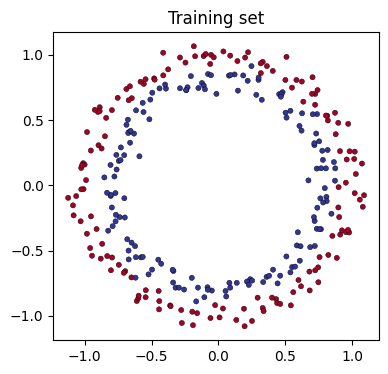

In [ ]:
train_X, train_Y, test_X, test_Y = load_circles()
print("train_X", tuple(train_X.shape), "| train_Y", tuple(train_Y.shape), "| test_X", tuple(test_X.shape))
plt.figure(figsize=(4.2, 4))
plt.scatter(train_X[:, 0], train_X[:, 1], c=train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 1.2 The model, by hand
`model` trains the 3-layer network `[2, 10, 5, 1]` with batch gradient descent. The only thing that changes between experiments is the **initialization**: `"zeros"`, `"random"` or `"he"`. The three functions are defined just after.

In [ ]:
def model(X, Y, initialization="he", lr=0.01, num_iters=15000, print_every=100):
    layer_dims = [X.shape[1], 10, 5, 1]
    if initialization == "zeros":
        params = initialize_parameters_zeros(layer_dims)
    elif initialization == "random":
        params = initialize_parameters_random(layer_dims)
    elif initialization == "he":
        params = initialize_parameters_he(layer_dims)
    costs = []
    for i in range(num_iters):
        A3, cache = forward_propagation(X, params)
        cost = compute_cost(A3, Y)
        grads = backward_propagation(X, Y, params, cache)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            costs.append(cost.item())
            if i % (5 * print_every) == 0:
                print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params, costs

def show(params, costs, title):
    print(f"train accuracy {accuracy(logits_by_hand(params), train_X, train_Y):.1f}% | "
          f"test accuracy {accuracy(logits_by_hand(params), test_X, test_Y):.1f}%")
    plot_costs(costs, title, 1000)
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(logits_by_hand(params), train_X, train_Y, lim=1.5); plt.show()

### 1.3 Zero initialization
All weights and biases start at 0. Shapes: $\mathbf{W}^{[l]}$ is $(n^{[l-1]}, n^{[l]})$ and $\mathbf{b}^{[l]}$ is $(1, n^{[l]})$.

In [ ]:
def initialize_parameters_zeros(layer_dims):
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.zeros(layer_dims[l - 1], layer_dims[l])
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

for k, v in initialize_parameters_zeros([3, 2, 1]).items():
    print(k, "=", v.tolist())

W1 = [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
b1 = [[0.0, 0.0]]
W2 = [[0.0], [0.0]]
b2 = [[0.0]]


In [ ]:
params_zeros, costs_zeros = model(train_X, train_Y, initialization="zeros")

Cost after iteration 0: 0.6931
Cost after iteration 500: 0.6931
Cost after iteration 1000: 0.6931
Cost after iteration 1500: 0.6931
Cost after iteration 2000: 0.6931
Cost after iteration 2500: 0.6931
Cost after iteration 3000: 0.6931
Cost after iteration 3500: 0.6931
Cost after iteration 4000: 0.6931
Cost after iteration 4500: 0.6931
Cost after iteration 5000: 0.6931
Cost after iteration 5500: 0.6931
Cost after iteration 6000: 0.6931
Cost after iteration 6500: 0.6931
Cost after iteration 7000: 0.6931
Cost after iteration 7500: 0.6931
Cost after iteration 8000: 0.6931
Cost after iteration 8500: 0.6931
Cost after iteration 9000: 0.6931
Cost after iteration 9500: 0.6931
Cost after iteration 10000: 0.6931
Cost after iteration 10500: 0.6931
Cost after iteration 11000: 0.6931
Cost after iteration 11500: 0.6931
Cost after iteration 12000: 0.6931
Cost after iteration 12500: 0.6931
Cost after iteration 13000: 0.6931
Cost after iteration 13500: 0.6931
Cost after iteration 14000: 0.6931
Cost afte

train accuracy 50.0% | test accuracy 50.0%


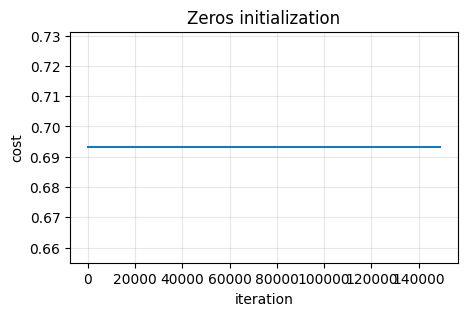

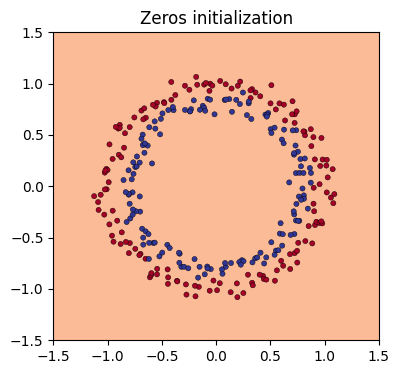

In [ ]:
show(params_zeros, costs_zeros, "Zeros initialization")

The cost never moves from $\log 2 = 0.6931$, and the model predicts the same class for every point: 50% accuracy.

**Why?** With all weights 0, every $\mathbf{Z}^{[l]}$ is 0, every ReLU outputs 0, and the sigmoid outputs $\sigma(0) = 0.5$ for every example. The gradients of $\mathbf{W}^{[2]}$ and $\mathbf{W}^{[3]}$ are products with activations that are all 0, and the error sent back through $\mathbf{W}^{[3]} = \mathbf{0}$ is 0: only $b^{[3]}$ could move, and it stays at 0 because the two classes are balanced. More generally, units that start equal compute the same thing and get the same update forever: the network cannot **break the symmetry**.

**Remember:** initialize $\mathbf{W}^{[l]}$ randomly. The biases $\mathbf{b}^{[l]}$ can start at 0.

### 1.4 Large random initialization
Random weights break the symmetry. Here we try **large** ones: `torch.randn(...) * 10`.

In [ ]:
def initialize_parameters_random(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * 100
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [ ]:
params_random, costs_random = model(train_X, train_Y, initialization="random")

Cost after iteration 0: 7.3742
Cost after iteration 500: 1.8294
Cost after iteration 1000: 1.3627
Cost after iteration 1500: 1.2516
Cost after iteration 2000: 1.1164
Cost after iteration 2500: 1.0568
Cost after iteration 3000: 1.4902
Cost after iteration 3500: 1.1078
Cost after iteration 4000: 1.0702
Cost after iteration 4500: 0.9736
Cost after iteration 5000: 1.1879
Cost after iteration 5500: 1.2408
Cost after iteration 6000: 0.9289
Cost after iteration 6500: 0.9268
Cost after iteration 7000: 0.9139
Cost after iteration 7500: 0.9147
Cost after iteration 8000: 1.2851
Cost after iteration 8500: 0.9254
Cost after iteration 9000: 0.9080
Cost after iteration 9500: 0.9250
Cost after iteration 10000: 0.8587
Cost after iteration 10500: 0.9322
Cost after iteration 11000: 0.9277
Cost after iteration 11500: 0.6851
Cost after iteration 12000: 1.1111
Cost after iteration 12500: 0.9279
Cost after iteration 13000: 0.7975
Cost after iteration 13500: 1.0434
Cost after iteration 14000: 0.9243
Cost afte

train accuracy 67.7% | test accuracy 65.0%


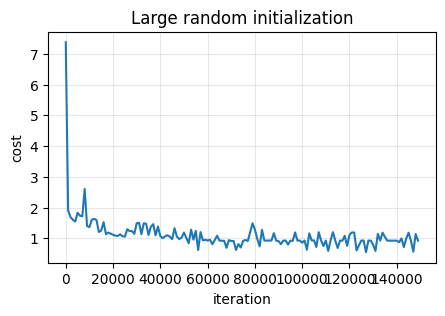

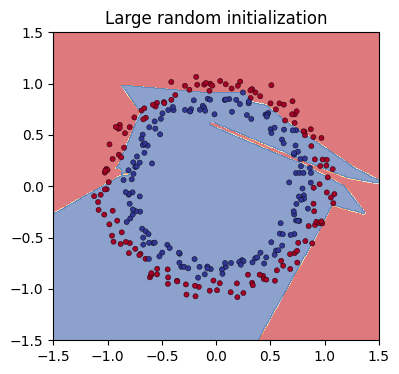

In [ ]:
show(params_random, costs_random, "Large random initialization")

The symmetry is broken and the model learns something, but slowly:

- The **first cost is very large.** With weights of size 10, $\mathbf{Z}^{[3]}$ is huge, the sigmoid outputs almost exactly 0 or 1, and every wrong prediction costs $-\log(\text{almost } 0)$. (Without the `clamp` in `compute_cost`, the cost would be `inf`.)
- Saturated outputs and huge activations make the optimization slow and unstable: the activations are close to **exploding**.

### 1.5 He initialization
For ReLU layers, He et al. (2015) scale the random weights by $\sqrt{2 / n^{[l-1]}}$ (lecture: "Weight initialization for deep networks").

In [ ]:
def initialize_parameters_he(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * (2 / layer_dims[l - 1]) ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [ ]:
params_he, costs_he = model(train_X, train_Y, initialization="he")

Cost after iteration 0: 0.7258
Cost after iteration 500: 0.6867
Cost after iteration 1000: 0.6828
Cost after iteration 1500: 0.6795
Cost after iteration 2000: 0.6759
Cost after iteration 2500: 0.6707
Cost after iteration 3000: 0.6642
Cost after iteration 3500: 0.6563
Cost after iteration 4000: 0.6454
Cost after iteration 4500: 0.6322
Cost after iteration 5000: 0.6168
Cost after iteration 5500: 0.5978
Cost after iteration 6000: 0.5745
Cost after iteration 6500: 0.5488
Cost after iteration 7000: 0.5179
Cost after iteration 7500: 0.4846
Cost after iteration 8000: 0.4455
Cost after iteration 8500: 0.4060
Cost after iteration 9000: 0.3544
Cost after iteration 9500: 0.3080
Cost after iteration 10000: 0.2687
Cost after iteration 10500: 0.2371
Cost after iteration 11000: 0.2109
Cost after iteration 11500: 0.1892
Cost after iteration 12000: 0.1709
Cost after iteration 12500: 0.1558
Cost after iteration 13000: 0.1431
Cost after iteration 13500: 0.1327
Cost after iteration 14000: 0.1240
Cost afte

train accuracy 97.7% | test accuracy 94.0%


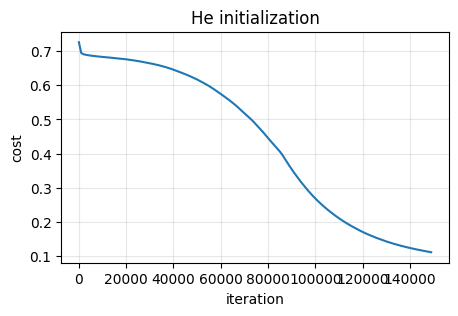

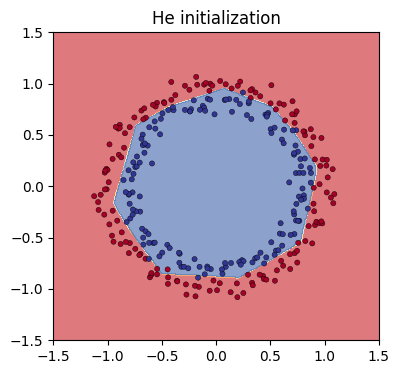

In [ ]:
show(params_he, costs_he, "He initialization")

### 1.6 Using PyTorch

| By hand | `torch.nn` |
|---|---|
| `torch.zeros(n_prev, n_l)` | `nn.init.zeros_(layer.weight)` |
| `torch.randn(n_prev, n_l) * 10` | `nn.init.normal_(layer.weight, mean=0.0, std=10.0)` |
| `torch.randn(n_prev, n_l) * (2 / n_prev) ** 0.5` | `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` |
| `torch.zeros(1, n_l)` | `nn.init.zeros_(layer.bias)` |

**One difference to remember:** `nn.Linear` stores its weight as `(n_out, n_in)`, the transpose of our $\mathbf{W}^{[l]}$, and computes `X @ weight.T + bias`. "Kaiming" is He's first name; by default it uses `n_in` (the "fan-in"), as in the lecture.

In [ ]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=5)
        self.layer_3 = nn.Linear(in_features=5, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR (logits)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

def init_weights(model, method, seed=3):
    torch.manual_seed(seed)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            if method == "zeros":
                nn.init.zeros_(layer.weight)
            elif method == "random":
                nn.init.normal_(layer.weight, mean=0.0, std=10.0)
            elif method == "he":
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model

model_0 = init_weights(CircleModel(), "he").to(device)
print(model_0)
print("layer_1.weight:", tuple(model_0.layer_1.weight.shape), "= (n_out, n_in) | std",
      round(model_0.layer_1.weight.std().item(), 3), "| sqrt(2 / n_in) =", round((2 / 2) ** 0.5, 3))

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=5, bias=True)
  (layer_3): Linear(in_features=5, out_features=1, bias=True)
  (relu): ReLU()
)
layer_1.weight: (10, 2) = (n_out, n_in) | std 0.676 | sqrt(2 / n_in) = 1.0


In [ ]:
check_model = CircleModel()
p = initialize_parameters_he([2, 10, 5, 1])
with torch.no_grad():
    for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
        layer.weight.copy_(p[f"W{l}"].T)          # (n_in, n_out) -> (n_out, n_in)
        layer.bias.copy_(p[f"b{l}"].flatten())

A3_hand, cache = forward_propagation(train_X, p)
grads = backward_propagation(train_X, train_Y, p, cache)
loss = nn.BCEWithLogitsLoss()(check_model(train_X), train_Y)
loss.backward()                                    # autograd

print(f"sigmoid(logits) vs A3: max difference {(torch.sigmoid(check_model(train_X)) - A3_hand).abs().max().item():.1e}")
for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
    print(f"dW{l}: max difference {(layer.weight.grad.T - grads[f'dW{l}']).abs().max().item():.1e} | "
          f"db{l}: max difference {(layer.bias.grad - grads[f'db{l}'].flatten()).abs().max().item():.1e}")

sigmoid(logits) vs A3: max difference 0.0e+00
dW1: max difference 1.9e-09 | db1: max difference 3.7e-09
dW2: max difference 3.7e-09 | db2: max difference 5.6e-09
dW3: max difference 3.0e-08 | db3: max difference 3.7e-09


In [ ]:
def train_and_test(model, loss_fn, optimizer, X_train, y_train, X_test, y_test, epochs, print_every=None):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)
    for epoch in range(epochs):
        ### Training
        model.train()
        y_logits = model(X_train)                       # 1. forward pass (logits)
        y_pred = torch.round(torch.sigmoid(y_logits))   #    logits -> probabilities -> labels
        loss = loss_fn(y_logits, y_train)               # 2. loss
        acc = accuracy_fn(y_true=y_train, y_pred=y_pred)
        optimizer.zero_grad()                           # 3. zero the gradients
        loss.backward()                                 # 4. backpropagation
        optimizer.step()                                # 5. gradient descent step

        ### Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_pred = torch.round(torch.sigmoid(test_logits))
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model

In [ ]:
torch.manual_seed(42)
model_0 = init_weights(CircleModel(), "he").to(device)
loss_fn = nn.BCEWithLogitsLoss()                                 # sigmoid + binary cross-entropy
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)
model_0 = train_and_test(model_0, loss_fn, optimizer, train_X, train_Y, test_X, test_Y, epochs=15000, print_every=100)

Epoch:     0 | Loss: 0.69057, Accuracy: 50.00% | Test loss: 0.69148, Test acc: 50.00%
Epoch:   100 | Loss: 0.68471, Accuracy: 51.67% | Test loss: 0.68563, Test acc: 50.00%
Epoch:   200 | Loss: 0.68217, Accuracy: 51.67% | Test loss: 0.68317, Test acc: 50.00%
Epoch:   300 | Loss: 0.68055, Accuracy: 52.33% | Test loss: 0.68171, Test acc: 52.00%
Epoch:   400 | Loss: 0.67924, Accuracy: 55.33% | Test loss: 0.68061, Test acc: 54.00%
Epoch:   500 | Loss: 0.67802, Accuracy: 55.33% | Test loss: 0.67959, Test acc: 54.00%
Epoch:   600 | Loss: 0.67683, Accuracy: 56.67% | Test loss: 0.67859, Test acc: 57.00%
Epoch:   700 | Loss: 0.67562, Accuracy: 57.33% | Test loss: 0.67753, Test acc: 58.00%
Epoch:   800 | Loss: 0.67436, Accuracy: 57.33% | Test loss: 0.67642, Test acc: 61.00%
Epoch:   900 | Loss: 0.67305, Accuracy: 58.00% | Test loss: 0.67530, Test acc: 60.00%
Epoch:  1000 | Loss: 0.67164, Accuracy: 58.67% | Test loss: 0.67409, Test acc: 60.00%
Epoch:  1100 | Loss: 0.67021, Accuracy: 59.00% | Test 

initialization      train     test
zeros               50.0%    50.0%
random              79.0%    76.0%
he                  98.7%    93.0%
default             97.3%    92.0%


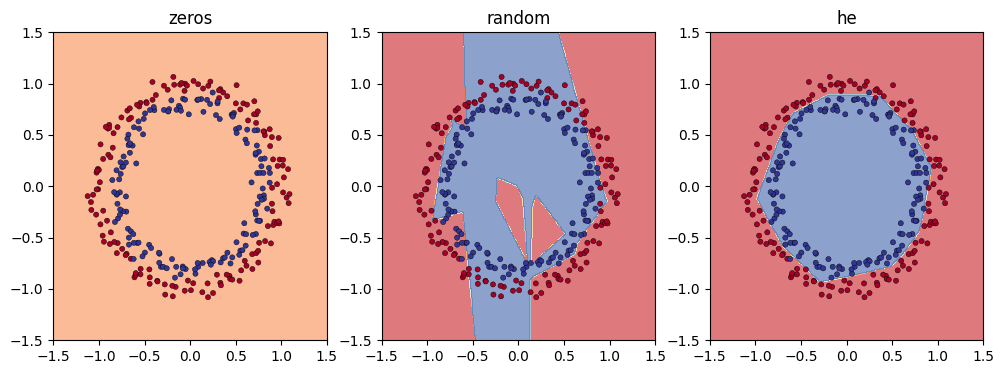

In [ ]:
results_init = {}
for method in ["zeros", "random", "he", "default"]:
    torch.manual_seed(3)
    m = CircleModel()                          # PyTorch's default initialization
    if method != "default":
        init_weights(m, method)
    m = m.to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.01)
    train_and_test(m, nn.BCEWithLogitsLoss(), opt, train_X, train_Y, test_X, test_Y, epochs=15000)
    results_init[method] = (accuracy(m, train_X, train_Y), accuracy(m, test_X, test_Y))

print(f"{'initialization':16s} {'train':>8s} {'test':>8s}")
for method, (tr, te) in results_init.items():
    print(f"{method:16s} {tr:7.1f}% {te:7.1f}%")

plt.figure(figsize=(12, 4))
for k, method in enumerate(["zeros", "random", "he"]):
    torch.manual_seed(3)
    m = init_weights(CircleModel(), method).to(device)
    train_and_test(m, nn.BCEWithLogitsLoss(), torch.optim.SGD(m.parameters(), lr=0.01), train_X, train_Y, test_X, test_Y, epochs=15000)
    plt.subplot(1, 3, k + 1); plt.title(method); plot_decision_boundary(m, train_X, train_Y, lim=1.5)
plt.show()

**What to remember from Part 1**
- Different initializations give very different results with the same network and the same training.
- Random weights break the symmetry; weights that are too large saturate the output and slow down learning.
- For ReLU networks, use He initialization: `nn.init.kaiming_normal_(w, nonlinearity="relu")`.

---
## 2 · Regularization

### 2.1 The data
A noisy 2-D dataset: 211 training points and 200 test points. The true boundary is a gentle curve, but the training labels contain mistakes: about 6% random errors, plus a few small **pockets** of wrong labels (for example, a region labeled by a careless annotator). The test labels contain only the random errors. A network that fits the pockets will generalize badly.

In [ ]:
def make_noisy_2d(m, seed, pockets=()):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, (m, 2))                                  # uniform in [-1, 1]^2
    Y = (X[:, 1] > 0.35 * np.sin(2.2 * X[:, 0]) - 0.1 * X[:, 0]).astype(float)
    flip = rng.random(m) < 0.06                                     # random label errors
    for cx, cy, r in pockets:                                       # pockets of wrong labels
        inside = (X[:, 0] - cx) ** 2 + (X[:, 1] - cy) ** 2 < r ** 2
        flip |= inside & (rng.random(m) < 0.7)
    Y[flip] = 1 - Y[flip]
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32).reshape(-1, 1)

train (211, 2) | test (200, 2) | fraction of class 1: 0.5


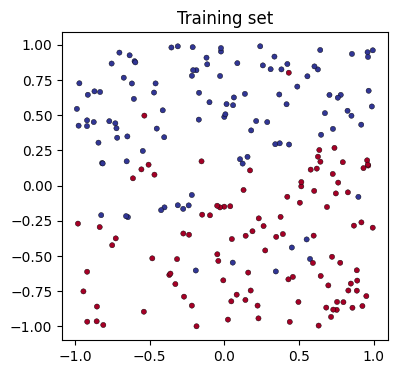

In [ ]:
POCKETS = [(-0.55, 0.05, 0.12), (0.1, 0.45, 0.10), (0.5, -0.45, 0.12), (-0.2, -0.55, 0.10)]
reg_train_X, reg_train_Y = make_noisy_2d(211, seed=0, pockets=POCKETS)
reg_test_X, reg_test_Y = make_noisy_2d(200, seed=1)
print("train", tuple(reg_train_X.shape), "| test", tuple(reg_test_X.shape), "| fraction of class 1:", round(reg_train_Y.mean().item(), 2))
plt.figure(figsize=(4.2, 4))
plt.scatter(reg_train_X[:, 0], reg_train_X[:, 1], c=reg_train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 2.2 The baseline model, by hand
The network is `[2, 20, 3, 1]`, initialized with $\sqrt{1/n^{[l-1]}}$ and trained for 30,000 iterations with $\alpha = 0.3$. `model_reg` can run in three modes:
- no regularization: `lambd = 0`, `keep_prob = 1`;
- **L2 regularization**: `lambd > 0` (we write `lambd` because `lambda` is a Python keyword);
- **dropout**: `keep_prob < 1`.

The L2 and dropout functions it calls are written in 2.3 and 2.4.

Cost after iteration 0: 0.7019
Cost after iteration 1000: 0.2248
Cost after iteration 2000: 0.2015
Cost after iteration 3000: 0.1888
Cost after iteration 4000: 0.1724
Cost after iteration 5000: 0.1520
Cost after iteration 6000: 0.1461
Cost after iteration 7000: 0.1349
Cost after iteration 8000: 0.1346
Cost after iteration 9000: 0.1272
Cost after iteration 10000: 0.1269
Cost after iteration 11000: 0.1317
Cost after iteration 12000: 0.1201
Cost after iteration 13000: 0.1168
Cost after iteration 14000: 0.1150
Cost after iteration 15000: 0.1024
Cost after iteration 16000: 0.1159
Cost after iteration 17000: 0.0775
Cost after iteration 18000: 0.1543
Cost after iteration 19000: 0.1825
Cost after iteration 20000: 0.0592
Cost after iteration 21000: 0.1235
Cost after iteration 22000: 0.0621
Cost after iteration 23000: 0.0894
Cost after iteration 24000: 0.0659
Cost after iteration 25000: 0.0662
Cost after iteration 26000: 0.0505
Cost after iteration 27000: 0.0750
Cost after iteration 28000: 0.050

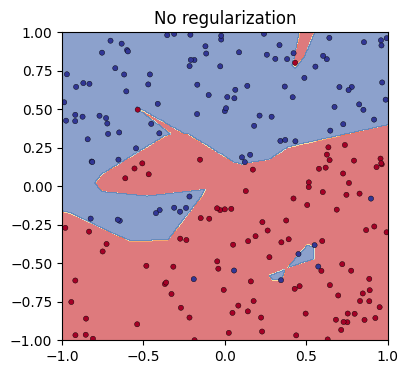

In [ ]:
def initialize_parameters(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) / layer_dims[l - 1] ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

def model_reg(X, Y, lr=0.3, num_iters=30000, lambd=0.0, keep_prob=1.0, print_every=1000, seed=1):
    params = initialize_parameters([X.shape[1], 20, 3, 1])
    gen = torch.Generator().manual_seed(seed)          # random masks for dropout
    for i in range(num_iters):
        if keep_prob == 1:
            A3, cache = forward_propagation(X, params)
        else:
            A3, cache = forward_propagation_with_dropout(X, params, keep_prob, gen)
        if lambd == 0:
            cost = compute_cost(A3, Y)
        else:
            cost = compute_cost_with_regularization(A3, Y, params, lambd)
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, params, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, params, cache, lambd)
        else:
            grads = backward_propagation_with_dropout(X, Y, params, cache, keep_prob)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params

def report(name, model):
    tr = accuracy(model, reg_train_X, reg_train_Y)
    te = accuracy(model, reg_test_X, reg_test_Y)
    print(f"{name}: train accuracy {tr:.1f}% | test accuracy {te:.1f}%")
    return tr, te

def plot_reg(model, title):
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(model, reg_train_X, reg_train_Y, lim=1.0); plt.show()

results_reg = {}
params_base = model_reg(reg_train_X, reg_train_Y)
results_reg["no regularization"] = report("no regularization", logits_by_hand(params_base))
plot_reg(logits_by_hand(params_base), "No regularization")

This is the **baseline**. Compare the training and the test accuracy, and look at the boundary: it bends around the pockets of wrong labels. The model is **overfitting** (high variance).

### 2.3 L2 regularization, by hand
The cost gets a penalty on the size of the weights (lecture: "L2 regularization: neural network"):
$$J_{\text{regularized}} = \underbrace{-\frac{1}{m}\sum_{i=1}^{m}\Big(y^{(i)}\log a^{[3](i)} + (1-y^{(i)})\log\big(1-a^{[3](i)}\big)\Big)}_{\text{cross-entropy cost}} + \underbrace{\frac{\lambda}{2m}\sum_{l=1}^{3}\lVert\mathbf{W}^{[l]}\rVert_F^2}_{\text{L2 cost}}$$
and, because the cost changed, every weight gradient gets an extra term: $d\mathbf{W}^{[l]} = (\text{from backprop}) + \frac{\lambda}{m}\mathbf{W}^{[l]}$. The biases are not regularized.

Cost after iteration 0: 0.7342
Cost after iteration 1000: 0.2991
Cost after iteration 2000: 0.2953
Cost after iteration 3000: 0.2932
Cost after iteration 4000: 0.2918
Cost after iteration 5000: 0.2906
Cost after iteration 6000: 0.2894
Cost after iteration 7000: 0.2888
Cost after iteration 8000: 0.2884
Cost after iteration 9000: 0.2881
Cost after iteration 10000: 0.2880
Cost after iteration 11000: 0.2879
Cost after iteration 12000: 0.2879
Cost after iteration 13000: 0.2879
Cost after iteration 14000: 0.2878
Cost after iteration 15000: 0.2879
Cost after iteration 16000: 0.2879
Cost after iteration 17000: 0.2879
Cost after iteration 18000: 0.2878
Cost after iteration 19000: 0.2878
Cost after iteration 20000: 0.2878
Cost after iteration 21000: 0.2877
Cost after iteration 22000: 0.2878
Cost after iteration 23000: 0.2878
Cost after iteration 24000: 0.2881
Cost after iteration 25000: 0.2877
Cost after iteration 26000: 0.2878
Cost after iteration 27000: 0.2878
Cost after iteration 28000: 0.287

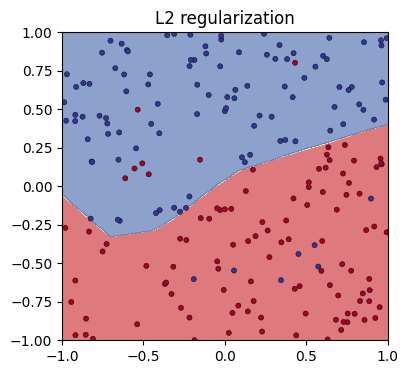

In [ ]:
def compute_cost_with_regularization(A3, Y, params, lambd):
    m = Y.shape[0]
    cross_entropy_cost = compute_cost(A3, Y)
    L2_cost = lambd / (2 * m) * sum((params[f"W{l}"] ** 2).sum() for l in [1, 2, 3])
    return cross_entropy_cost + L2_cost

def backward_propagation_with_regularization(X, Y, params, cache, lambd):
    m = X.shape[0]
    grads = backward_propagation(X, Y, params, cache)     # the usual gradients
    for l in [1, 2, 3]:
        grads[f"dW{l}"] = grads[f"dW{l}"] + lambd / m * params[f"W{l}"]
    return grads

params_L2 = model_reg(reg_train_X, reg_train_Y, lambd=0.7)
results_reg["L2, lambda = 0.7"] = report("L2, lambda = 0.7", logits_by_hand(params_L2))
plot_reg(logits_by_hand(params_L2), "L2 regularization")

Compare with the baseline: the training accuracy should go **down** and the test accuracy **up**, and the boundary should no longer bend around the pockets. Smaller weights give a simpler, smoother function.

`backward_propagation_with_regularization` reuses `backward_propagation` and only adds $\frac{\lambda}{m}\mathbf{W}^{[l]}$: the regularization changes nothing else.

### 2.4 Dropout, by hand
Inverted dropout on the two hidden layers (lecture: "Dropout regularization"). For layer 1, at **every** iteration:
1. draw a mask `D1` of the same shape as `A1`, $(m, n^{[1]})$, with 1 with probability `keep_prob` and 0 otherwise;
2. `A1 = A1 * D1`: shut down the dropped units;
3. `A1 = A1 / keep_prob`: keep the expected value of `A1` unchanged.

In the backward pass, apply the **same** mask and the same scaling to `dA1`. Same for layer 2. No dropout on the input or the output layer.

Cost after iteration 0: 0.7146
Cost after iteration 1000: 0.3121
Cost after iteration 2000: 0.2387
Cost after iteration 3000: 0.2588
Cost after iteration 4000: 0.2646
Cost after iteration 5000: 0.2700
Cost after iteration 6000: 0.2178
Cost after iteration 7000: 0.2327
Cost after iteration 8000: 0.1939
Cost after iteration 9000: 0.2010
Cost after iteration 10000: 0.2034
Cost after iteration 11000: 0.2310
Cost after iteration 12000: 0.2051
Cost after iteration 13000: 0.2800
Cost after iteration 14000: 0.2138
Cost after iteration 15000: 0.1889
Cost after iteration 16000: 0.1984
Cost after iteration 17000: 0.2429
Cost after iteration 18000: 0.2305
Cost after iteration 19000: 0.2011
Cost after iteration 20000: 0.1984
Cost after iteration 21000: 0.1670
Cost after iteration 22000: 0.2071
Cost after iteration 23000: 0.1704
Cost after iteration 24000: 0.1822
Cost after iteration 25000: 0.2624
Cost after iteration 26000: 0.2132
Cost after iteration 27000: 0.2170
Cost after iteration 28000: 0.183

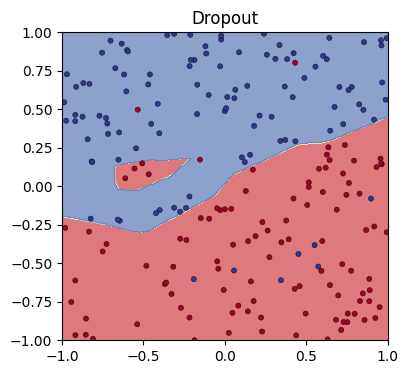

In [ ]:
def forward_propagation_with_dropout(X, params, keep_prob, gen):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    D1 = (torch.rand(A1.shape, generator=gen) < keep_prob).float()    # step 1
    A1 = A1 * D1                                                      # step 2
    A1 = A1 / keep_prob                                               # step 3
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    D2 = (torch.rand(A2.shape, generator=gen) < keep_prob).float()
    A2 = A2 * D2 / keep_prob
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, D1, A1, Z2, D2, A2, Z3, A3)
    return A3, cache

def backward_propagation_with_dropout(X, Y, params, cache, keep_prob):
    m = X.shape[0]
    Z1, D1, A1, Z2, D2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dA2 = dA2 * D2 / keep_prob                 # same mask, same scaling
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dA1 = dA1 * D1 / keep_prob
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

params_drop = model_reg(reg_train_X, reg_train_Y, keep_prob=0.86)
results_reg["dropout, keep_prob = 0.86"] = report("dropout, keep_prob = 0.86", logits_by_hand(params_drop))
plot_reg(logits_by_hand(params_drop), "Dropout")

### 2.5 Using PyTorch
| By hand | PyTorch |
|---|---|
| `compute_cost_with_regularization` and $+\frac{\lambda}{m}\mathbf{W}^{[l]}$ in backprop | `weight_decay=λ/m` in the optimizer |
| masks `D1`, `D2`, divide by `keep_prob` | `nn.Dropout(p=1 - keep_prob)` after each hidden ReLU |
| no dropout at test time | `model.eval()` (and `model.train()` to go back) |

Two details:
- **`p` in `nn.Dropout` is the probability of *dropping* a unit**, so `p = 1 - keep_prob`.
- `weight_decay` applies to every parameter it is given. To regularize only the weights, as in the lecture, give the optimizer two **parameter groups**.

In [ ]:
class RegModel(nn.Module):
    def __init__(self, keep_prob=1.0):
        super().__init__()
        self.layer_1 = nn.Linear(2, 20)
        self.layer_2 = nn.Linear(20, 3)
        self.layer_3 = nn.Linear(3, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=1 - keep_prob)      # p = probability of DROPPING a unit

    def forward(self, x):
        x = self.dropout(self.relu(self.layer_1(x)))
        x = self.dropout(self.relu(self.layer_2(x)))
        return self.layer_3(x)                          # logits

def make_optimizer(model, lr, lambd, m):
    weights = [p for name, p in model.named_parameters() if name.endswith("weight")]
    biases = [p for name, p in model.named_parameters() if name.endswith("bias")]
    return torch.optim.SGD([{"params": weights, "weight_decay": lambd / m},
                            {"params": biases, "weight_decay": 0.0}], lr=lr)

print(RegModel(keep_prob=0.86))

RegModel(
  (layer_1): Linear(in_features=2, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=3, bias=True)
  (layer_3): Linear(in_features=3, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.14, inplace=False)
)


**Check 1: `weight_decay` does exactly what our L2 code does.** One step with `weight_decay=λ/m` versus one step with the penalty written in the cost:

In [ ]:
lambd, m = 0.7, reg_train_X.shape[0]
torch.manual_seed(0); model_a = RegModel()
torch.manual_seed(0); model_b = RegModel()

# (a) weight_decay in the optimizer
opt_a = make_optimizer(model_a, lr=0.3, lambd=lambd, m=m)
loss_a = nn.BCEWithLogitsLoss()(model_a(reg_train_X), reg_train_Y)
opt_a.zero_grad(); loss_a.backward(); opt_a.step()

# (b) the L2 penalty written in the cost, plain SGD
opt_b = torch.optim.SGD(model_b.parameters(), lr=0.3)
penalty = lambd / (2 * m) * sum((layer.weight ** 2).sum() for layer in [model_b.layer_1, model_b.layer_2, model_b.layer_3])
loss_b = nn.BCEWithLogitsLoss()(model_b(reg_train_X), reg_train_Y) + penalty
opt_b.zero_grad(); loss_b.backward(); opt_b.step()

diff = max((pa - pb).abs().max().item() for pa, pb in zip(model_a.parameters(), model_b.parameters()))
print(f"max difference between the parameters after one step: {diff:.1e}")

max difference between the parameters after one step: 0.0e+00


Identical up to rounding. Note that `loss_a` does **not** contain the penalty: with `weight_decay`, the regularization lives in the update rule, not in the printed loss.

**Check 2: `nn.Dropout` is inverted dropout.** On a tensor of ones, in training mode and in evaluation mode:

In [ ]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
drop.train()
print("train mode:", drop(torch.ones(10)))
drop.eval()
print("eval mode: ", drop(torch.ones(10)))

train mode: tensor([0., 0., 2., 0., 0., 0., 2., 2., 0., 2.])
eval mode:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In training mode, about half of the values are set to 0 and the others are divided by `keep_prob = 0.5`, i.e. multiplied by 2. In evaluation mode, `nn.Dropout` does nothing. This is why the loop calls `model.train()` before the training step and `model.eval()` before testing.

Finally, the three models of this part, trained with the same loop as in Part 1:

PyTorch | no regularization: train accuracy 99.1% | test accuracy 82.5%
PyTorch | L2, lambda = 0.7: train accuracy 91.5% | test accuracy 93.5%
PyTorch | dropout, keep_prob = 0.86: train accuracy 95.7% | test accuracy 88.5%


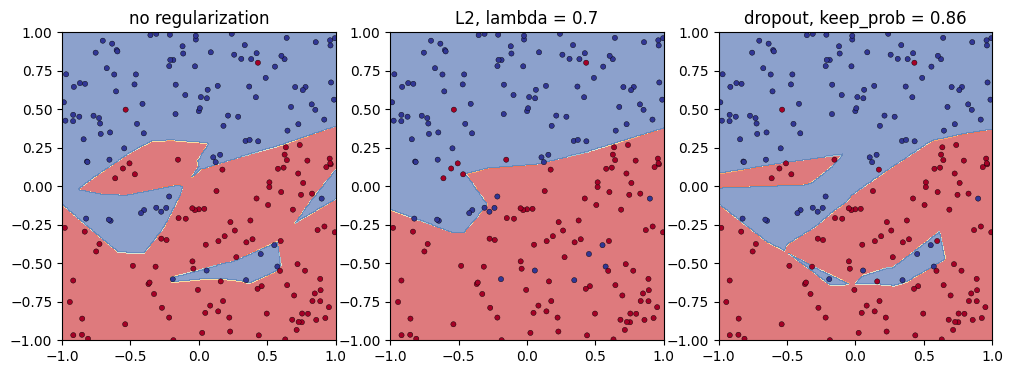

In [ ]:
def train_reg_model(lambd=0.0, keep_prob=1.0, lr=0.3, epochs=30000, seed=3, print_every=None):
    torch.manual_seed(seed)
    model = RegModel(keep_prob).to(device)
    optimizer = make_optimizer(model, lr, lambd, reg_train_X.shape[0])
    return train_and_test(model, nn.BCEWithLogitsLoss(), optimizer, reg_train_X, reg_train_Y,
                          reg_test_X, reg_test_Y, epochs=epochs, print_every=print_every)

results_nn = {}
models_nn = {}
for name, kw in [("no regularization", {}), ("L2, lambda = 0.7", {"lambd": 0.7}), ("dropout, keep_prob = 0.86", {"keep_prob": 0.86})]:
    models_nn[name] = train_reg_model(**kw)
    results_nn[name] = report(f"PyTorch | {name}", models_nn[name])

plt.figure(figsize=(12, 4))
for k, name in enumerate(models_nn):
    plt.subplot(1, 3, k + 1); plt.title(name); plot_decision_boundary(models_nn[name], reg_train_X, reg_train_Y, lim=1.0)
plt.show()

The numbers are not identical to the hand-written version (`nn.Linear` draws its random numbers differently, and the dropout masks differ), but they should lead to the same conclusions.

### 2.6 Conclusions

In [ ]:
print(f"{'model':28s} {'by hand':>18s} {'PyTorch':>18s}")
print(f"{'':28s} {'train':>8s} {'test':>8s}   {'train':>8s} {'test':>8s}")
for name in results_reg:
    (a, b), (c, d) = results_reg[name], results_nn[name]
    print(f"{name:28s} {a:7.1f}% {b:7.1f}%   {c:7.1f}% {d:7.1f}%")

model                                   by hand            PyTorch
                                train     test      train     test
no regularization               96.2%    87.5%      99.1%    82.5%
L2, lambda = 0.7                93.4%    95.0%      91.5%    93.5%
dropout, keep_prob = 0.86       95.3%    94.5%      95.7%    88.5%


**What to remember from Part 2**
- Regularization **lowers the training accuracy** and **raises the test accuracy**: it stops the network from fitting the noise.
- L2 adds $\frac{\lambda}{2m}\sum_l\lVert\mathbf{W}^{[l]}\rVert_F^2$ to the cost and $\frac{\lambda}{m}\mathbf{W}^{[l]}$ to each gradient; in PyTorch, `weight_decay=λ/m`.
- Dropout is used **only during training**, in the forward **and** the backward pass, with the division by `keep_prob`; in PyTorch, `nn.Dropout(p=1 - keep_prob)` with `model.train()` / `model.eval()`.
- $\lambda$ and `keep_prob` are hyperparameters, chosen on a dev set.

---
## ★ Assignment (to submit)

### Exercise 1 · The moons dataset
Make a binary classification dataset with scikit-learn's `make_moons()`: 1000 samples, `noise=0.07`, `random_state=42`. Turn it into PyTorch tensors (`float32`; labels of shape $(m, 1)$) and split it into 80% training and 20% test data with `train_test_split(..., test_size=0.2, random_state=42)`. Plot the training set.

Training X:  torch.Size([800, 2])
Training Y:  torch.Size([800, 1])
Test X:  torch.Size([200, 2])
Test Y:  torch.Size([200, 1])


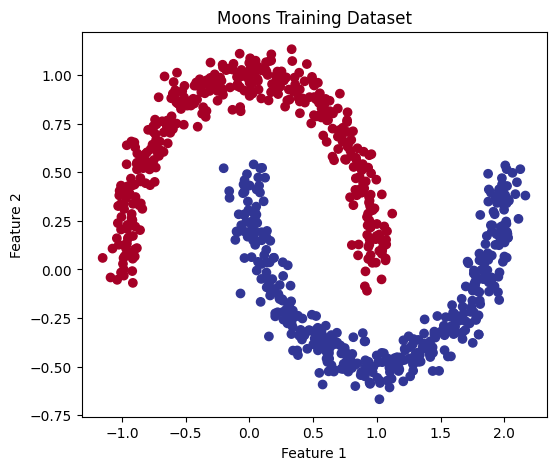

In [ ]:
# Exercise 1
X, y = make_moons(n_samples=1000, noise=0.07, random_state=42)
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1,1)
train_X, test_X, train_Y, test_Y = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training X: ", train_X.shape)
print("Training Y: ", train_Y.shape)
print("Test X: ", test_X.shape)
print("Test Y: ", test_Y.shape)

plt.figure(figsize=(6,5))
plt.scatter(train_X[:,0], train_X[:,1], c=train_Y.flatten(), cmap=plt.cm.RdYlBu)
plt.title("Moons Training Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Report of Exercise 1: The Moons Dataset

## 1.1 Objective

The purpose of this exercise is to create a binary classification dataset using `make_moons()`.

Binary classification means that the model must classify each data point into one of two possible classes: class 0 or class 1.

The moons dataset contains two moon-shaped groups. These groups are not separated by a straight line, so a neural network needs to learn a non-linear decision boundary.

## 1.2 Why do we choose these values?

**1. Number of samples: 1000**

We use 1000 samples to provide enough data for the neural network to learn the patterns.

A larger dataset can give the model more examples to learn from. However, it also requires more time to train.

**2. Noise = 0.07**

Noise adds small random changes to the positions of the data points.

We choose 0.07 because it creates a slightly more difficult classification problem while keeping the two moon-shaped groups recognizable.

- Very low noise: The classes are easier to separate.
- Higher noise: The classes become more mixed, making classification harder.

**3. Random state = 42**

`random_state=42` makes the dataset reproducible.

This means that running the code again produces the same random dataset, allowing us to compare results fairly.

The number 42 has no special mathematical meaning. It is simply a fixed seed.

**4. Test size = 0.2**

We divide the dataset into:

- 80% training data = 800 samples.
- 20% testing data = 200 samples.

The training set is used to teach the model. The testing set is used to evaluate how well the model works on data it has not seen during training.

We use a larger training set because the model needs enough examples to learn the patterns.

## 1.3 Why do we convert the data into PyTorch tensors?

```python
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
```

PyTorch uses tensors to perform mathematical operations and train neural networks.

- `float32`: Used for numerical calculations involving features and binary labels.
- `reshape(-1, 1)`: Changes the labels into a column with one value per sample.

For example:

Before reshaping:

```text
[0, 1, 0, 1]
```

After reshaping:

```text
[[0],
 [1],
 [0],
 [1]]
```

The labels have shape `(1000, 1)` because our output layer will produce one prediction for each sample.

## 1.4 Why do we plot the training data?

The scatter plot allows us to see the shape and distribution of the data.

It helps us understand:

- Whether the two classes are separated.
- Whether there is overlap between the classes.
- Why a straight-line classifier may not work well.
- Why a neural network with hidden layers is useful.

## 1.5 What do the results tell us?

The expected dataset shapes are:

| Dataset | Shape |
|---|---|
| Training X | (800, 2) |
| Training Y | (800, 1) |
| Testing X | (200, 2) |
| Testing Y | (200, 1) |

The two features represent the x and y coordinates of each data point.

**Conclusion:**

The moons dataset creates a non-linear binary classification problem. We use it to test whether a neural network can learn a curved decision boundary instead of only a straight line.

ទិន្នន័យដែលមានរាងដូចព្រះចន្ទ បានបង្កើត Binary Classification ដែលមានរាងដូចខ្សែកោង។ យើងប្រើវាដើម្បីតេស្តថា Neural Network អាចរៀនទិន្នន័យទាំងនោះបានល្អឬអត់។



### Exercise 2 · A model for the moons
Build a model by subclassing `nn.Module`, with non-linear activation functions, capable of fitting the moons. It should output **one logit**. Initialize every `nn.Linear` with **He initialization** and zero biases (Part 1.6). Print the model and its number of parameters.

In [ ]:
# Exercise 2
class MoonModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.layers = nn.Sequential(
        nn.Linear(2,64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32,1)
    )

    # He initialization
    for layer in self.layers:
      if isinstance(layer, nn.Linear):
        nn.init.kaiming_normal(layer.weight)
        nn.init.zeros_(layer.bias)

  def forward(self, x):
    return self.layers(x)

moon_model = MoonModel().to(device)
print(moon_model)
total_params = sum(p.numel() for p in moon_model.parameters())
print("Total parameters: ", total_params)

MoonModel(
  (layers): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Total parameters:  2305


/tmp/ipykernel_400/2220527990.py:16: FutureWarning: `nn.init.kaiming_normal` is now deprecated in favor of `nn.init.kaiming_normal_`.
  nn.init.kaiming_normal(layer.weight)


# Report of Exercise 2: Build a Neural Network for the Moons Dataset

## 2.1 Objective

The purpose of this exercise is to build a neural network using `nn.Module`.

The network must learn the non-linear patterns in the moons dataset and produce one output logit for binary classification.

Our model has the following architecture:

```text
Input layer: 2 neurons
       |
       v
Hidden layer 1: 64 neurons
       |
      ReLU
       |
       v
Hidden layer 2: 32 neurons
       |
      ReLU
       |
       v
Output layer: 1 neuron
       |
       v
    Logit
```

## 2.2 Why do we choose these layer sizes?

**Input layer: 2 neurons**

The dataset has two features, so the input layer needs two neurons.

Each neuron receives one feature:

- First neuron: Feature 1 (x coordinate).
- Second neuron: Feature 2 (y coordinate).

**First hidden layer: 64 neurons**

We choose 64 neurons to give the network enough capacity to learn complex patterns.

A hidden layer learns different combinations of the input features.

**Second hidden layer: 32 neurons**

We use another hidden layer to allow the network to learn more complex patterns by combining the features learned by the previous layer.

The number of neurons decreases from 64 to 32. This is a design choice, not a fixed rule.

A larger network can learn more complex patterns, but it may also overfit or take longer to train.

**Output layer: 1 neuron**

The problem has only two classes.

Therefore, one output logit is enough for binary classification.

The output is not directly a probability. We can apply sigmoid to convert it into a probability between 0 and 1.

## 2.3 Why do we use ReLU?

ReLU stands for Rectified Linear Unit.

Its formula is:

$$
ReLU(z)=\max(0,z)
$$

It works as follows:

- If the input is positive, it returns the input.
- If the input is negative, it returns zero.

We use ReLU because it introduces non-linearity into the network.

Without non-linear activation functions, multiple linear layers would behave like one linear layer. The model would not be able to learn the curved patterns in the moons dataset.

ReLU is also computationally simple and helps reduce the vanishing gradient problem compared with some older activation functions.

## 2.4 Why do we use He initialization?

```python
nn.init.kaiming_normal_(layer.weight)
nn.init.zeros_(layer.bias)
```

He initialization gives the weights suitable random starting values.

We use it because our hidden layers use ReLU.

If all weights started at zero, neurons in the same layer would learn the same thing because they would receive the same gradients. This is called the symmetry problem.

Random initialization helps different neurons learn different features.

He initialization also helps keep the scale of activations and gradients more stable as they pass through layers.

The bias values are initialized to zero because there is no need to give every neuron an arbitrary starting offset.

## 2.5 Why do we count the parameters?

The model contains trainable weights and biases.

For a linear layer:

$$\text{Parameters} = (n_{in}\times n_{out})+n_{out}
$$
For our model:

**Layer 1:**

$$
(2\times64)+64=192
$$

**Layer 2:**

$$
(64\times32)+32=2080
$$

**Output layer:**

$$
(32\times1)+1=33
$$

Total:

$$
192+2080+33=\boxed{2305}
$$

The model has 2305 trainable parameters.

## 2.6 What do the results tell us?

The printed model confirms the architecture and the number of neurons in each layer.

The parameter count tells us how many trainable values the model needs to learn.

A model with more parameters has more flexibility, but it may also need more data and can be more likely to overfit.

**Conclusion:**

We build a neural network with two hidden layers and ReLU activation to learn the non-linear patterns in the moons dataset. He initialization gives the model suitable starting weights for ReLU-based learning.

យើងបានបង្កើត Neural Network ដែលមាន Hidden Layers ពីរ និងប្រើ ReLU Activation ដើម្បីរៀនពី Non-linear នៅក្នុង Moons Dataset។ He Initialization ជួយអោយតម្លៃដំបូងទៅ Weights ដែលសមស្របសម្រាប់ការរៀនដោយប្រើ ReLU។

### Exercise 3 · Loss and optimizer
Set up a loss function for binary classification that works with **logits**, and an SGD optimizer (batch gradient descent). Explain in one sentence why `nn.BCEWithLogitsLoss` is preferred to `nn.Sigmoid()` + `nn.BCELoss()`.

In [ ]:
# Exercise 3
loss.fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(
    moon_model.parameters(),
    lr = 0.1
)
print(loss_fn)
print(optimizer)

BCEWithLogitsLoss()
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


nn.BCEWithLogitsLoss() is preferred because it combines sigmoid and binary cross-entropy into one numerically more stable calculation, reducing the risk of numerical errors.

# Report of Exercise 3: Loss Function and Optimizer

## 3.1 Objective

The purpose of this exercise is to select a suitable loss function and optimizer for binary classification.

We use:

```python
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.SGD(
    moon_model.parameters(),
    lr=0.1
)
```

## 3.2 Why do we choose BCEWithLogitsLoss?

BCE stands for Binary Cross-Entropy.

It measures the difference between the predicted values and the actual labels.

Its mathematical formula is:

$$
J=-\frac{1}{m}\sum_{i=1}^{m}
[y^{(i)}\log(a^{(i)})
+(1-y^{(i)})\log(1-a^{(i)})]
$$

Where:

- \(m\): Number of samples.
- \(y\): Actual label (0 or 1).
- \(a\): Predicted probability.

A lower loss means the predictions are closer to the correct labels.

We choose `BCEWithLogitsLoss()` because it combines sigmoid and binary cross-entropy in one function.

The model outputs logits, so we do not need to apply sigmoid before passing the predictions to the loss function.

It is also more numerically stable than applying sigmoid and then using `BCELoss()` separately.

**Important:** During prediction, we still apply sigmoid when we want to convert logits into probabilities.

## 3.3 Why do we choose SGD?

SGD stands for Stochastic Gradient Descent.

It updates the model's parameters using gradients calculated from the loss.

The general update formula is:

$$
W_{new}=W_{old}-\alpha\frac{\partial J}{\partial W}
$$

$$
b_{new}=b_{old}-\alpha\frac{\partial J}{\partial b}
$$

Where:

- \(W\): Weights.
- \(b\): Biases.
- \(J\): Loss function.
- \(\alpha\): Learning rate.

In this exercise, we use batch gradient descent because we calculate the loss using the entire training dataset before updating the parameters.

## 3.4 Why do we choose learning rate = 0.1?

The learning rate controls how much the weights change during each update.

We choose 0.1 as an initial experimental value to allow the model to learn at a reasonable speed.

If the learning rate is too small:

- The model learns very slowly.
- It may need many epochs to reach good accuracy.

If the learning rate is too large:

- The model may jump over a good solution.
- The loss may increase or fluctuate.
- Training may become unstable.

There is no universal best learning rate. We must test different values and observe the training results.

## 3.5 What do the results tell us?

At this stage, we have prepared the model for training.

The loss function tells the model how wrong its predictions are.

The optimizer uses gradients to update the weights and biases to reduce the loss.

**Conclusion:**

We use `BCEWithLogitsLoss()` because our task is binary classification and our model produces logits. We use SGD to update the parameters, starting with a learning rate of 0.1.

យើងប្រើ `BCEWithLogitsLoss()` ព្រោះបញ្ហារបស់យើងគឺ Binary Classification ហើយម៉ូដែលបញ្ចេញតម្លៃជា Logits។ យើងប្រើ SGD ដើម្បី update តម្លៃ Parameters ដោយចាប់ផ្តើមពី Learning Rate ស្មើ 0.1។


### Exercise 4 · Training and testing loop
Write a training and testing loop (you may reuse `train_and_test` or write your own) and train the model until it reaches **more than 96% test accuracy**. Print the training and test loss and accuracy every 100 epochs. If you do not reach 96%, change the learning rate, the number of epochs or the number of hidden units, and explain what you changed.

In [ ]:
# Exercise 4
def train_moon_model(model, epochs=3000):
  for epoch in range(epochs):

    model.train()
    train_logits = model(train_X.to(device))
    train_loss = loss_fn(train_logits, train_Y.to(device))
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    model.eval()
    with torch.inference_mode():
      test_logits = model(test_X.to(device))
      test_loss = loss_fn(test_logits, test_Y.to(device))

      train_pred = torch.round(torch.sigmoid(train_logits))
      test_pred = torch.round(torch.sigmoid(test_logits))

      train_acc = accuracy_fn(train_Y.to(device), train_pred)
      test_acc = accuracy_fn(test_Y.to(device), test_pred)

    if epoch % 100 == 0:
      print(
          f"Epoch: {epoch:4d} | "
          f"Train loss: {train_loss.item():.4f} | "
          f"Train acc: {train_acc:.2f}% | "
          f"Test loss: {test_loss.item():.4f} | "
          f"Test acc: {test_acc:.2f}%"
      )
train_moon_model(moon_model, epochs=3000)
print("Final training accuracy: ", accuracy(moon_model, train_X, train_Y))
print("Final testing accuracy: ", accuracy(moon_model, test_X, test_Y))




Epoch:    0 | Train loss: 0.7913 | Train acc: 50.00% | Test loss: 0.5560 | Test acc: 72.00%
Epoch:  100 | Train loss: 0.2087 | Train acc: 89.50% | Test loss: 0.2096 | Test acc: 91.00%
Epoch:  200 | Train loss: 0.1774 | Train acc: 92.25% | Test loss: 0.1801 | Test acc: 92.00%
Epoch:  300 | Train loss: 0.1455 | Train acc: 94.25% | Test loss: 0.1473 | Test acc: 94.50%
Epoch:  400 | Train loss: 0.1075 | Train acc: 96.50% | Test loss: 0.1065 | Test acc: 97.00%
Epoch:  500 | Train loss: 0.0736 | Train acc: 97.75% | Test loss: 0.0693 | Test acc: 98.00%
Epoch:  600 | Train loss: 0.0480 | Train acc: 99.25% | Test loss: 0.0425 | Test acc: 100.00%
Epoch:  700 | Train loss: 0.0317 | Train acc: 99.62% | Test loss: 0.0265 | Test acc: 100.00%
Epoch:  800 | Train loss: 0.0219 | Train acc: 99.75% | Test loss: 0.0177 | Test acc: 100.00%
Epoch:  900 | Train loss: 0.0161 | Train acc: 100.00% | Test loss: 0.0126 | Test acc: 100.00%
Epoch: 1000 | Train loss: 0.0123 | Train acc: 100.00% | Test loss: 0.0095 |

# Report of Exercise 4: Training and Testing Loop

## 4.1 Objective

The purpose of this exercise is to train the model and evaluate its performance.

We want to reach more than 96% test accuracy.

We use:

- Learning rate = 0.1.
- Epochs = 3000.
- Loss function = BCEWithLogitsLoss.
- Optimizer = SGD.

## 4.2 What is an epoch?

An epoch means that the model has completed one full pass through the training dataset.

For example, if we have 800 training samples:

- Epoch 1: The model processes all 800 samples.
- Epoch 2: The model processes all 800 samples again.
- Epoch 3000: The model has completed 3000 full passes.

More epochs give the model more opportunities to learn.

However, too many epochs can cause overfitting.

## 4.3 Why do we choose 3000 epochs?

We choose 3000 epochs as an initial training duration because the model needs enough updates to learn the curved decision boundary.

This is an experimental choice rather than a value required by the assignment.

If the model has low accuracy and the loss is still decreasing, we may need more epochs.

If the training accuracy is high but testing accuracy becomes worse, the model may be overfitting.

We should not automatically increase epochs without checking the results.

## 4.4 Why do we use zero_grad()?

```python
optimizer.zero_grad()
```

PyTorch accumulates gradients by default.

This means gradients from previous updates would be added to new gradients if we did not clear them.

We use `zero_grad()` to reset the gradients before calculating new ones.

## 4.5 Why do we use backward()?

```python
train_loss.backward()
```

This calculates the gradients of the loss with respect to the model's trainable parameters.

In simple words, it tells us how each weight and bias contributes to the error.

The gradients are then used by the optimizer to update the parameters.

## 4.6 Why do we use optimizer.step()?

```python
optimizer.step()
```

This updates the weights and biases using the gradients.

The model repeats this process to reduce the loss over time.

The complete training process is:

```text
Input data
    |
    v
Forward propagation
    |
    v
Calculate loss
    |
    v
Calculate gradients
    |
    v
Update parameters
    |
    v
Repeat for the next epoch
```

## 4.7 Why do we use model.train() and model.eval()?

`model.train()` tells PyTorch that the model is in training mode.

`model.eval()` tells PyTorch that the model is in evaluation mode.

These modes are important for layers such as dropout and batch normalization.

Our moons model does not contain dropout or batch normalization, but using these modes is still good practice.

## 4.8 Why do we use torch.inference_mode()?

```python
with torch.inference_mode():
```

We use this when evaluating the model.

It prevents PyTorch from calculating gradients because we are not updating the model during testing.

This saves memory and makes evaluation more efficient.

## 4.9 Why do we use sigmoid and round?

```python
train_pred = torch.round(torch.sigmoid(train_logits))
```

The output of the model is a logit, not a probability.

Sigmoid converts it into a probability:
$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

The probability is between 0 and 1.

We use `round()` to convert the probability into a class:

- Probability below 0.5 becomes class 0.
- Probability equal to or above 0.5 becomes class 1.

## 4.10 Why do we print results every 100 epochs?

```python
if epoch % 100 == 0:
```

Printing results after every epoch creates too much output.

Printing every 100 epochs allows us to monitor the learning process without producing too many lines.

We can observe:

- Whether training loss decreases.
- Whether testing loss decreases.
- Whether accuracy improves.
- Whether the model begins to overfit.

## 4.11 How do we interpret the results?

**Training loss**

Shows how much error the model makes on the training data.

A decreasing training loss means the model is learning the training patterns.

**Testing loss**

Shows how much error the model makes on unseen testing data.

A low testing loss means the model makes better predictions on new data.

**Training accuracy**

Shows the percentage of training samples classified correctly.

**Testing accuracy**

Shows the percentage of testing samples classified correctly.

The assignment requires more than 96% testing accuracy.

We should compare training and testing accuracy:

| Situation | Meaning |
|---|---|
| Both high | The model learns well and generalizes well. |
| Training high, testing low | Possible overfitting. |
| Both low | Possible underfitting or poor training. |
| Both improve | The model is learning useful patterns. |

**Conclusion:**

The training loop repeatedly updates the model to reduce the loss. We monitor training and testing performance to check whether the model learns the data and generalizes to unseen examples.

Training Loop ធ្ធ្វើបច្ចុប្បន្នភាពម៉ូដែលម្តងហើយម្តងទៀត ដើម្បីកាត់បន្ថយ Loss។ យើងមើលលទ្ធផល Training និង Testing ដើម្បីពិនិត្យមើលថាម៉ូដែលអាចរៀនពីទិន្នន័យ និងព្យាករណ៍លើទិន្នន័យថ្មីបានល្អឬអត់។

### Exercise 5 · Decision boundaries
Plot the decision boundary of your trained model on the training set and on the test set, side by side, with `plot_decision_boundary`.

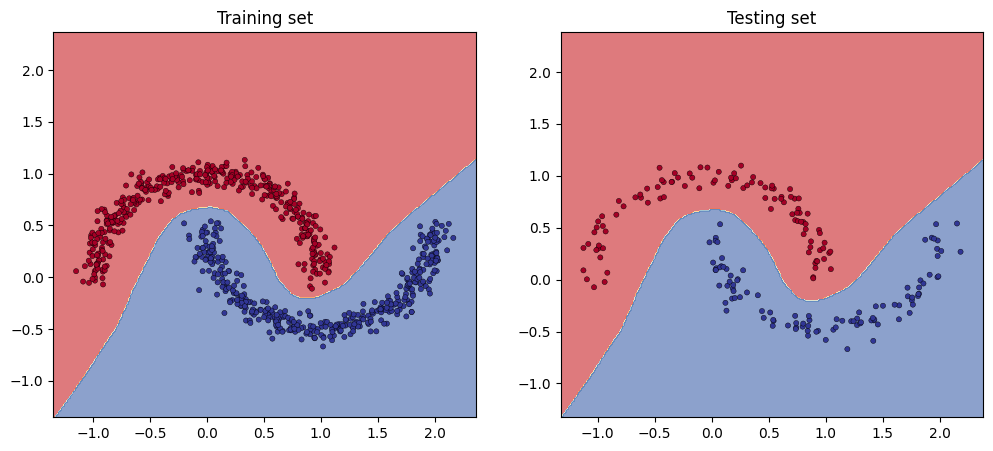

In [ ]:
# Exercise 5
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.title("Training set")
plot_decision_boundary(moon_model, train_X, train_Y)

plt.subplot(1, 2, 2)
plt.title("Testing set")
plot_decision_boundary(moon_model, test_X, test_Y)

plt.show()

# Report of Exercise 5: Decision Boundaries

## 5.1 Objective

The purpose of this exercise is to visualize how the trained neural network separates the two classes.

We plot two graphs:

1. Training set decision boundary.
2. Testing set decision boundary.

Both graphs use the same trained model.

## 5.2 What is a decision boundary?

A decision boundary is the line or curve that separates different predicted classes.

For example:

- One region represents class 0.
- Another region represents class 1.

The neural network learns this boundary from the training data.

Unlike a linear model, a neural network with hidden layers and ReLU can create a curved and more complex boundary.

## 5.3 Why do we plot both training and testing sets?

**Training set:**

Shows how well the model fits the examples used during training.

**Testing set:**

Shows how well the model classifies examples it did not use during training.

Comparing both helps us understand whether the model has learned general patterns or simply memorized the training data.

## 5.4 How do we interpret the graphs?

A good decision boundary should separate the two classes correctly.

If most points are inside the correct predicted regions, the model is performing well.

If many points appear in the wrong regions, the model makes classification errors.

We should also compare the two graphs:

- Similar performance on both sets suggests good generalization.
- A very good training graph but a poor testing graph suggests overfitting.
- Poor performance on both graphs suggests underfitting.

**Conclusion:**

Decision boundaries provide a visual explanation of how the neural network classifies the data. Comparing training and testing graphs helps us understand the model's ability to generalize.

Decision Boundaries ផ្តល់រូបភាពដែលបង្ហាញអំពីរបៀបដែល Neural Network ចាត់ថ្នាក់របស់ទិន្នន័យ។ ការប្រៀបធៀបក្រាប Training និង Testing ជួយឱ្យយើងយល់ពីសមត្ថភាពរបស់ម៉ូដែលក្នុងការព្យាករណ៍លើទិន្នន័យថ្មី។


### Exercise 6 · Tanh in pure PyTorch
Write `tanh(z)` using only `torch.exp` and arithmetic: $\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$. Compare it with `torch.tanh` on `torch.linspace(-5, 5, 101)` (print the maximum difference) and plot both.

*Optional:* what happens with your function for $z = 100$? Rewrite it as $\tanh(z) = 2\sigma(2z) - 1$ and explain why this version is safer.

Maximum difference:  1.1920928955078125e-07


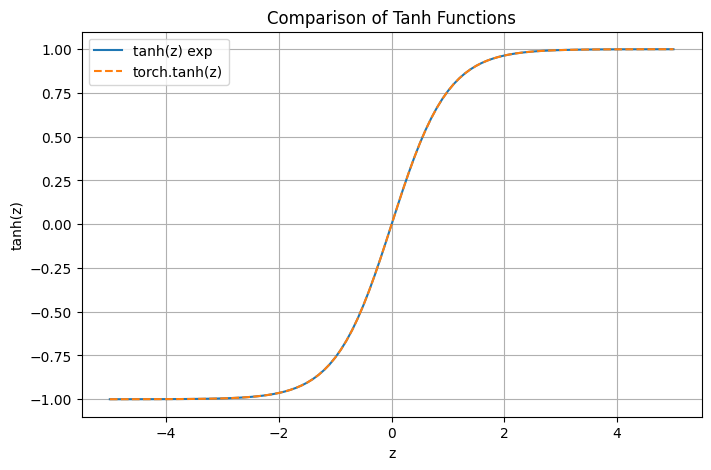

In [ ]:
# Exercise 6
def tanh(z):
  return (torch.exp(z)-torch.exp(-z))/(torch.exp(z)+torch.exp(-z))

z = torch.linspace(-5, 5, 101)

result1 = tanh(z)
result2 = torch.tanh(z)

max_difference = torch.max(torch.abs(result1 - result2))
print("Maximum difference: ", max_difference.item())

plt.figure(figsize=(8,5))
plt.plot(z, result1, label="tanh(z) exp")
plt.plot(z, result2, "--", label="torch.tanh(z)")
plt.xlabel("z")
plt.ylabel("tanh(z)")
plt.title("Comparison of Tanh Functions")
plt.legend()
plt.grid()
plt.show()


In [ ]:
def safe_tanh(z):
  return 2 * torch.sigmoid(2 * z) -1

z = torch.tensor([100.0])

print("Original tanh: ", tanh(z))
print("Safer tanh: ", safe_tanh(z))
print("PyTorch tanh: ", torch.tanh(z))

Original tanh:  tensor([nan])
Safer tanh:  tensor([1.])
PyTorch tanh:  tensor([1.])


For large values such as 100, torch.exp(100) can overflow and produce infinity. The sigmoid-based version is safer because sigmoid handles large positive and negative values more stably.

# Report of Exercise 6: Implement Tanh Using PyTorch

## 6.1 Objective

The purpose of this exercise is to implement the Tanh activation function manually using PyTorch operations and compare it with the built-in `torch.tanh()`.

The mathematical formula is:

$$
\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}
$$

We implement this formula using:

```python
def my_tanh(z):
    return (torch.exp(z) - torch.exp(-z)) / (
        torch.exp(z) + torch.exp(-z)
    )
```

## 6.2 What is Tanh?

Tanh stands for Hyperbolic Tangent.

It is an activation function that converts input values into a range between -1 and 1.

Its output behaves as follows:

| Input | Approximate output |
|---|---|
| Large negative value | -1 |
| 0 | 0 |
| Large positive value | 1 |

The graph has an S-shaped curve.

Tanh is useful because it introduces non-linearity and produces both positive and negative outputs.

Unlike sigmoid, which produces values between 0 and 1, Tanh is centered around zero.

## 6.3 Why do we use torch.linspace(-5, 5, 101)?

```python
z = torch.linspace(-5, 5, 101)
```

This creates 101 evenly spaced values between -5 and 5.

We choose this range because it shows the main behavior of Tanh:

- Negative inputs approach -1.
- Zero produces 0.
- Positive inputs approach 1.

Using 101 points gives us enough values to create a smooth graph.

## 6.4 Why do we compare with torch.tanh()?

```python
result1 = my_tanh(z)
result2 = torch.tanh(z)
```

We calculate Tanh using two methods:

1. Our own mathematical implementation.
2. PyTorch's built-in implementation.

We compare them to check whether our formula is correct.

We calculate the maximum difference:

$$
D_{max}=\max|Tanh_{manual}-Tanh_{PyTorch}|
$$

If the maximum difference is very close to zero, the two implementations produce almost identical results.

A very small difference can happen because of floating-point precision.

## 6.5 Why do we plot both functions?

The graph allows us to visually compare the two implementations.

If the two curves overlap, it means our manually implemented function behaves like PyTorch's built-in Tanh.

## 6.6 Optional: Why can Tanh have numerical problems for z = 100?

When we calculate:

$$
e^{100}
$$

the value becomes extremely large.

Computers have a limited range for representing floating-point numbers.

Therefore, `torch.exp(100)` may overflow and become infinity.

This can cause an incorrect result:

$$
\frac{\infty-\text{small value}}
{\infty+\text{small value}}
$$

The mathematical answer should be close to 1, but the computer may produce an invalid value such as NaN.

## 6.7 Why is the sigmoid version safer?

We can rewrite Tanh as:

$$
\tanh(z)=2\sigma(2z)-1
$$

Where:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

We implement it as:

```python
def safe_tanh(z):
    return 2 * torch.sigmoid(2 * z) - 1
```

This version avoids directly calculating both \(e^z\) and \(e^{-z}\).

PyTorch's sigmoid implementation handles large values more safely.

**Conclusion:**

The manual implementation helps us understand the mathematical formula of Tanh. Comparing it with `torch.tanh()` confirms that the formula is correct. The sigmoid-based version also demonstrates why numerical stability is important in deep learning.

ការអនុវត្ត Tanh ដោយដៃជួយឱ្យយើងយល់ពីរូបមន្តគណិតវិទ្យារបស់ tanh។ ការប្រៀបធៀបជាមួយ `torch.tanh()` បានបញ្ជាក់ថារូបមន្តដែលយើងបានសរសេរដោយដៃគឺត្រឹមត្រូវ។ Sigmoid Version ក៏បង្ហាញឱ្យយើងឃើញថា Numerical Stability មានសារៈសំខាន់យ៉ាងប៉ុណ្ណានៅក្នុង Deep Learning។

### Exercise 7 · A multi-class problem: spirals
Create the 3-class spiral dataset of CS231n with the code below (300 points), turn it into tensors (`X` as `float32`, `y` as `long` of shape $(m,)$), and split it 80/20 with `random_state=42`.

Then:
- build a model capable of fitting the data; it outputs **3 logits** (one per class);
- use `nn.CrossEntropyLoss()` (softmax + cross-entropy, Lecture 2) and an optimizer (optional extension: `torch.optim.Adam`; you may have to try several learning rates);
- write a training and testing loop for the multi-class case (predicted class = `argmax` of the logits) and reach **more than 95% test accuracy**;
- plot the decision boundaries on the training and test sets with `plot_decision_boundary` (it handles several classes).

```python
# Code for creating a spiral dataset from CS231n
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()
```

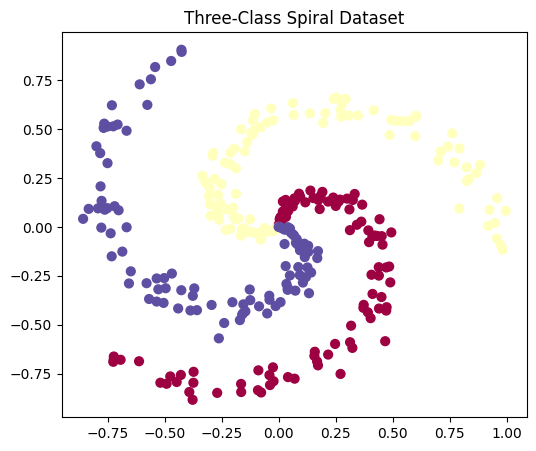

Training:  torch.Size([240, 2]) torch.Size([240])
Testing:  torch.Size([60, 2]) torch.Size([60])
SpiralModel(
  (layers): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)
Parameters:  8835
Epoch:    0 | Train loss: 1.1382 | Train acc: 31.25% | Test loss: 0.8250 | Test acc: 48.33%


/tmp/ipykernel_400/2837346461.py:50: FutureWarning: `nn.init.kaiming_normal` is now deprecated in favor of `nn.init.kaiming_normal_`.
  nn.init.kaiming_normal(layer.weight)


Epoch:  500 | Train loss: 0.0147 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Epoch: 1000 | Train loss: 0.0139 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Epoch: 1500 | Train loss: 0.0139 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Epoch: 2000 | Train loss: 0.0138 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Epoch: 2500 | Train loss: 0.0138 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Epoch: 3000 | Train loss: 0.0138 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Epoch: 3500 | Train loss: 0.0139 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Epoch: 4000 | Train loss: 0.0138 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Epoch: 4500 | Train loss: 0.0138 | Train acc: 99.17% | Test loss: 0.0000 | Test acc: 100.00%
Training accuracy:  99.16666666666667
Testing accuracy:  100.0


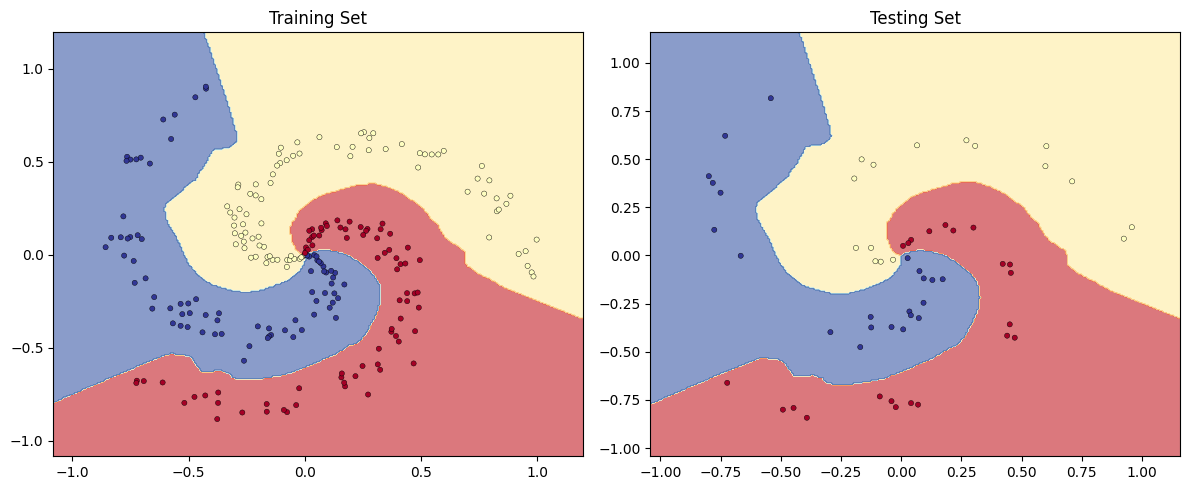

In [ ]:
# Exercise 7: data
np.random.seed(42)

N = 100
D = 2
K = 3

X = np.zeros((N * K, D))
y = np.zeros(N * K, dtype="uint8")

for j in range(K):
  ix = range(N * j, N * (j+1))

  r = np.linspace(0.0, 1, N)
  t = np.linspace(j * 4, (j +1) * 4, N) + np.random.randn(N) * 0.2

  X[ix] = np.c_[r *np.sin(t), r * np.cos(t)]
  y[ix] = j

plt.figure(figsize=(6,5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.title("Three-Class Spiral Dataset")
plt.show()

X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

train_X, test_X, train_Y, test_Y = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training: ", train_X.shape, train_Y.shape)
print("Testing: ", test_X.shape, test_Y.shape)

# model
class SpiralModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.layers = nn.Sequential(
        nn.Linear(2, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 3)
    )

    for layer in self.layers:
      if isinstance(layer, nn.Linear):
        nn.init.kaiming_normal(layer.weight)
        nn.init.zeros_(layer.bias)

  def forward(self, x):
    return self.layers(x)

spiral_model = SpiralModel().to(device)

print(spiral_model)

print("Parameters: ", sum(p.numel() for p in spiral_model.parameters()))

# loss, optimizer, training and testing loop
spiral_loss = nn.CrossEntropyLoss()
spiral_optimizer = torch.optim.Adam(
    spiral_model.parameters(),
    lr=0.01
)

def train_spiral_model(model, epochs=5000):
  X_train = train_X.to(device)
  Y_train = train_Y.to(device)
  X_test = test_X.to(device)
  Y_test = test_Y.to(device)

  for epoch in range(epochs):
    model.train()

    train_logits = model(X_train)
    train_loss = spiral_loss(train_logits, Y_train)

    spiral_optimizer.zero_grad()
    train_loss.backward()
    spiral_optimizer.step()

    model.eval()

    with torch.inference_mode():
      test_logits = model(X_test)
      test_loss = spiral_loss(test_logits, Y_test)

      train_pred = train_logits.argmax(dim=1)
      test_pred = test_logits.argmax(dim=1)

      train_acc = accuracy_fn(Y_train, train_pred)
      test_acc = accuracy_fn(Y_test, test_pred)

    if epoch % 500 == 0:
      print(
          f"Epoch: {epoch:4d} | "
          f"Train loss: {train_loss.item():.4f} | "
          f"Train acc: {train_acc:.2f}% | "
          f"Test loss: {test_loss.item():.4f} | "
          f"Test acc: {test_acc:.2f}%"
      )

train_spiral_model(spiral_model, epochs=5000)

print("Training accuracy: ", accuracy(spiral_model, train_X, train_Y))
print("Testing accuracy: ", accuracy(spiral_model, test_X, test_Y))

# decision boundaries
plt.figure(figsize=(12,5))
plt.subplot(1, 2, 1)
plt.title("Training Set")
plot_decision_boundary(spiral_model, train_X, train_Y)

plt.subplot(1, 2, 2)
plt.title("Testing Set")
plot_decision_boundary(spiral_model, test_X, test_Y)
plt.tight_layout()
plt.show()

# Report of Exercise 7: Multi-Class Classification with Spiral Data

## 7.1 Objective

The purpose of this exercise is to build a neural network that classifies spiral data into three different classes.

This is a multi-class classification problem because there are three possible output classes:

- Class 0.
- Class 1.
- Class 2.

Unlike the moons dataset, which contains two classes, the spiral dataset has a more complex pattern.

The model must learn curved decision boundaries to separate the three classes.

## 7.2 Why do we choose these dataset values?

**N = 100**

This means each class contains 100 data points.

Since there are three classes:

$$
Total\ samples=100\times3=300
$$

**D = 2**

Each data point has two features:

- x coordinate.
- y coordinate.

Therefore, the input layer needs two neurons.

**K = 3**

There are three classes, so the output layer needs three neurons.

**Random seed = 42**

This makes the random spiral data reproducible.

**Random noise = 0.2**

The code adds random noise to the angle values.

Noise makes the classification problem less perfect and more realistic.

It prevents the model from learning only an overly simple pattern.

## 7.3 Why do we use float32 for X and long for y?

```python
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)
```

The features are numerical values, so we use `float32`.

The class labels are integer class IDs, so we use `long`.

`CrossEntropyLoss()` expects class labels as integer values with the `long` data type.

The label shape is `(300,)` because each sample has one class ID.

For example:

```text
[0, 0, 0, 1, 1, 1, 2, 2, 2]
```

## 7.4 Why do we split the data 80/20?

We use:

- 80% training data = 240 samples.
- 20% testing data = 60 samples.

The training data teaches the model.

The testing data evaluates how well the model works on unseen examples.

We use `random_state=42` to make the split reproducible.

## 7.5 Why do we choose this network architecture?

Our model is:

```text
Input: 2 neurons
       |
       v
Hidden layer 1: 128 neurons
       |
      ReLU
       |
       v
Hidden layer 2: 64 neurons
       |
      ReLU
       |
       v
Output: 3 neurons
       |
       v
  3 class logits
```

**Why 128 neurons in the first hidden layer?**

The spiral dataset has complex and curved patterns.

We choose 128 neurons to give the network enough capacity to learn these patterns.

**Why 64 neurons in the second hidden layer?**

The second hidden layer combines the features learned by the first layer.

Using 64 neurons provides another level of feature learning without making the network unnecessarily large.

These sizes are experimental choices, not values required by the assignment.

**Why 3 output neurons?**

Each output neuron represents one class.

The network produces three logits:

$$
Z=[z_0,z_1,z_2]
$$

The highest logit represents the predicted class.

## 7.6 Why do we use CrossEntropyLoss?

```python
spiral_loss = nn.CrossEntropyLoss()
```

Cross-entropy loss is suitable for multi-class classification.

It measures how different the predicted class distribution is from the correct class.

It combines softmax and cross-entropy internally.

Softmax converts logits into probabilities:

$$
P(y=i)=\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

For example:

```text
Class 0: 0.10
Class 1: 0.80
Class 2: 0.10
```

The model predicts class 1 because it has the highest probability.

We do not need to apply softmax before `CrossEntropyLoss()`. We should pass the raw logits directly.

## 7.7 Why do we use Adam instead of SGD?

We use:

```python
spiral_optimizer = torch.optim.Adam(
    spiral_model.parameters(),
    lr=0.01
)
```

Adam stands for Adaptive Moment Estimation.

It adjusts the learning rate for individual parameters based on estimates of past gradients.

Adam often works well for complex neural networks because it can adapt the size of parameter updates during training.

We choose Adam because the spiral problem is more complex than the moons problem and may be difficult to train using a simple SGD configuration.

## 7.8 Why do we choose learning rate = 0.01?

The learning rate controls how much the parameters change during each update.

We choose 0.01 as an experimental starting value for Adam.

A higher learning rate may help the model learn faster, but it can make training unstable.

A lower learning rate may make training more stable but slower.

We can compare values such as:

- 0.1: Larger updates.
- 0.01: Moderate starting value.
- 0.001: Smaller updates.

The best value depends on the dataset and model.

## 7.9 Why do we choose 5000 epochs?

We choose 5000 epochs to give the model enough opportunities to learn the complex spiral patterns.

The assignment requires more than 95% test accuracy.

If the model has not reached this target, we can experiment with:

- Increasing the number of epochs.
- Changing the learning rate.
- Increasing hidden units.
- Adjusting the architecture.

We should check both training and testing results to avoid overfitting.

## 7.10 Why do we use argmax(dim=1)?

```python
train_pred = train_logits.argmax(dim=1)
```

The model produces three logits for every sample.

`argmax(dim=1)` selects the position of the highest logit.

For example:

```text
Logits = [1.2, 3.5, 0.8]
```

The highest value is 3.5, which is at index 1.

Therefore, the predicted class is 1.

We use this method because we want the class with the highest predicted score.

## 7.11 What do the results tell us?

The assignment requires more than 95% test accuracy.

We examine:

- Training loss: How much error the model makes on training data.
- Testing loss: How much error it makes on testing data.
- Training accuracy: How well it classifies training samples.
- Testing accuracy: How well it classifies unseen samples.

If both training and testing accuracy are high, the model has learned the spiral patterns successfully.

If training accuracy is high but testing accuracy is low, the model may be overfitting.

## 7.12 Why do we plot the decision boundaries?

The decision boundary shows how the model separates the three classes.

A good result should show three regions that follow the spiral patterns.

We plot both training and testing data to understand whether the model can generalize beyond the examples used during training.

**Conclusion:**

The spiral dataset is a more difficult multi-class classification problem. We use a deeper network, ReLU activation, CrossEntropyLoss and Adam to learn the complex spiral patterns and classify the data into three classes.

Spiral Dataset គឺជា Multi-class Classification ដែលមានភាពស្មុគស្មាញ។ យើងប្រើ Neural Network ដែលមានភាពស៊ាំញ៊ាំជាងមុន រួមជាមួយ ReLU, CrossEntropyLoss និង Adam ដើម្បីរៀនពីទិន្ន័យ Spiral និងចាត់ថ្នាក់ទិន្នន័យទៅជា Classes ចំនួនបី។


### Exercise 8 · Regularization on the spirals (TP3)
Train a **much larger** spiral model (for example two hidden layers of 128 units) for long enough that it overfits: training accuracy near 100%, and a visible gap with the test accuracy. Then train the same model with
- **L2 regularization** (`weight_decay` on the weights only, as in Part 2.5), and
- **dropout** (`nn.Dropout`),

keeping everything else equal. Report the training and test accuracy of the three models in a small table, plot the three decision boundaries, and answer in a markdown cell: which model would you choose, and why? Which set should be used to choose `weight_decay` and the dropout rate in a real project?

Training without regularization
Epoch 0: Train acc: 33.33% | Test acc: 51.67%
Epoch 500: Train acc: 98.75% | Test acc: 100.00%
Epoch 1000: Train acc: 99.17% | Test acc: 100.00%
Epoch 1500: Train acc: 99.17% | Test acc: 100.00%
Epoch 2000: Train acc: 99.17% | Test acc: 100.00%
Epoch 2500: Train acc: 99.17% | Test acc: 100.00%
Epoch 3000: Train acc: 99.17% | Test acc: 100.00%
Epoch 3500: Train acc: 99.17% | Test acc: 100.00%
Epoch 4000: Train acc: 99.17% | Test acc: 100.00%
Epoch 4500: Train acc: 99.17% | Test acc: 100.00%

Training with L2 regularization
Epoch 0: Train acc: 45.83% | Test acc: 46.67%
Epoch 500: Train acc: 98.75% | Test acc: 100.00%
Epoch 1000: Train acc: 99.17% | Test acc: 100.00%
Epoch 1500: Train acc: 98.75% | Test acc: 100.00%
Epoch 2000: Train acc: 99.17% | Test acc: 100.00%
Epoch 2500: Train acc: 99.17% | Test acc: 100.00%
Epoch 3000: Train acc: 98.75% | Test acc: 100.00%
Epoch 3500: Train acc: 98.75% | Test acc: 100.00%
Epoch 4000: Train acc: 99.17% | Test acc: 100

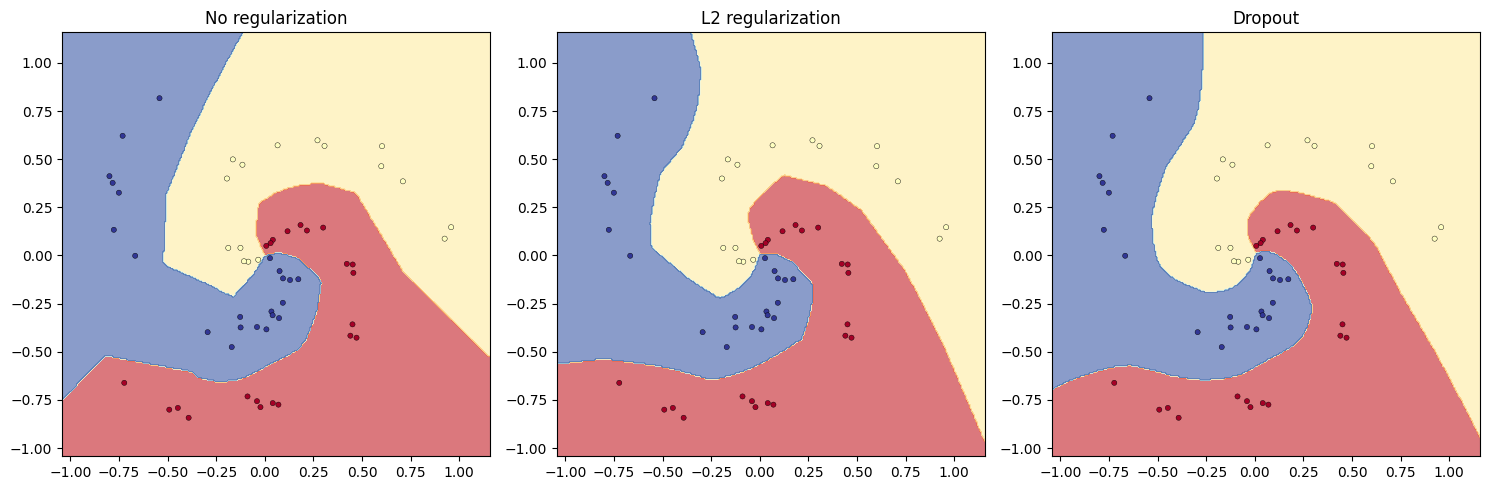

In [ ]:
# Exercise 8

# create a larger model

class LargeSpiralModel(nn.Module):
  def __init__(self, dropout_rate=0.0):
    super().__init__()

    self.layer1 = nn.Linear(2, 128)
    self.layer2 = nn.Linear(128, 128)
    self.layer3 = nn.Linear(128, 3)

    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(p=dropout_rate)

    for layer in [self.layer1, self.layer2, self.layer3]:
      nn.init.kaiming_normal_(layer.weight)
      nn.init.zeros_(layer.bias)

  def forward(self, x):
    x = self.relu(self.layer1(x))
    x = self.dropout(x)
    x = self.relu(self.layer2(x))
    x = self.dropout(x)

    return self.layer3(x)

# Create a training function
def train_large_model(model, weight_decay=0.0, epochs=5000):
  model = model.to(device)
  weights = []
  biases = []

  for name, param, in model.named_parameters():
    if name.endswith("weight"):
      weights.append(param)
    else:
      biases.append(param)

  lambd = 0.7
  m = len(train_X)

  optimizer = torch.optim.Adam([
      {"params": weights, "weight_decay": lambd / m},
      {"params": biases, "weight_decay": 0.0}
  ], lr=0.01)

  loss_fn = nn.CrossEntropyLoss()

  X_train = train_X.to(device)
  Y_train = train_Y.to(device)
  X_test = test_X.to(device)
  Y_test = test_Y.to(device)

  for epoch in range(epochs):
    model.train()

    train_logits = model(X_train)
    train_loss = loss_fn(train_logits, Y_train)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    model.eval()

    with torch.inference_mode():
      test_logits = model(X_test)
      test_loss = loss_fn(test_logits, Y_test)

      train_acc = accuracy_fn(
          Y_train, train_logits.argmax(dim=1)
      )

      test_acc = accuracy_fn(
          Y_test, test_logits.argmax(dim=1)
      )

    if epoch % 500 == 0:
      print(
          f"Epoch {epoch}: "
          f"Train acc: {train_acc:.2f}% | "
          f"Test acc: {test_acc:.2f}%"
      )


  return model

# Train the three models
torch.manual_seed(42)
print("Training without regularization")
model_no_reg = LargeSpiralModel(dropout_rate=0.0)
model_no_reg = train_large_model(model_no_reg)

print("\nTraining with L2 regularization")
model_l2 = LargeSpiralModel(dropout_rate=0.0)
model_l2 = train_large_model(model_l2, weight_decay=0.001)

print("\nTraining with dropout")
model_dropout = LargeSpiralModel(dropout_rate=0.3)
model_dropout = train_large_model(model_dropout)
print("\n")

# Compare accuracy
models = {
    "No regularization" : model_no_reg,
    "L2 regularization" : model_l2,
    "Dropout" : model_dropout
}

print(f"{'Model':25s} {'Train Accuracy':>15s} {'Test Accuracy':>15s}")

for name, model in models.items():
  train_acc = accuracy(model, train_X, train_Y)
  test_acc = accuracy(model, test_X, test_Y)
  print(f"{name:25s} {train_acc:.2f}% {test_acc:.2f}%")

# Plot three decision boundaries
plt.figure(figsize=(15 ,5))
for i, (name, model) in enumerate(models.items()):
  plt.subplot(1, 3, i+1)
  plt.title(name)

  plot_decision_boundary(model, test_X, test_Y)

plt.tight_layout()
plt.show()


### Discussion

**1. Which model would you choose, and why?**

I would choose the model with the best test accuracy because it performs better on unseen data. Regularization helps reduce overfitting by preventing the model from learning too much noise from the training data.

**2. Which dataset should be used to choose `weight_decay` and the dropout rate in a real project?**

The validation set should be used to select `weight_decay` and the dropout rate. The test set should only be used for the final evaluation of the model to avoid data leakage.

# Report of Exercise 8: Regularization on the Spiral Dataset

## 8.1 Objective

The purpose of this exercise is to understand overfitting and compare three different models:

1. Model without regularization.
2. Model with L2 regularization.
3. Model with dropout.

We use a larger neural network to make overfitting easier to observe.

The assignment asks us to train the model long enough to reach nearly 100% training accuracy and create a visible difference between training and testing accuracy.

Then, we apply regularization to see whether the model can generalize better.

## 8.2 Why do we use a larger model?

Our architecture is:

```text
Input: 2 neurons
       |
       v
Hidden layer 1: 128 neurons
       |
      ReLU
       |
     Dropout
       |
       v
Hidden layer 2: 128 neurons
       |
      ReLU
       |
     Dropout
       |
       v
Output: 3 neurons
```

We use 128 neurons in each hidden layer to give the network more learning capacity.

A larger network can learn more detailed patterns.

However, it can also learn noise or unnecessary details from the training data.

This makes it useful for studying overfitting.

## 8.3 Why do we use He initialization again?

```python
nn.init.kaiming_normal_(layer.weight)
nn.init.zeros_(layer.bias)
```

We use He initialization because the hidden layers use ReLU.

It provides suitable starting weights and helps maintain stable activation and gradient scales during training.

We use zero biases because we want the network to begin without arbitrary bias values.

## 8.4 What is overfitting?

Overfitting happens when a model learns the training data too closely, including noise and unnecessary details.

For example:

| Training accuracy | Testing accuracy | Interpretation |
|---|---|---|
| 99% | 85% | Possible overfitting |
| 95% | 94% | Better generalization |
| 70% | 68% | Possible underfitting |

The main problem with overfitting is that the model performs well on training data but poorly on new data.

This is why we need regularization.

## 8.5 Model 1: Without Regularization

The first model uses:

```python
model_no_reg = LargeSpiralModel(dropout_rate=0.0)
```

We do not apply L2 regularization or dropout.

This model is our baseline.

A baseline is a model used for comparison with other models.

We expect it to fit the training data very well because it has many neurons and no regularization to limit its learning.

However, it may overfit.

**What do the results tell us?**

If training accuracy is close to 100% but testing accuracy is noticeably lower, it suggests that the model has learned the training data too closely.

This gives us a reason to try regularization.

## 8.6 Model 2: L2 Regularization

L2 regularization adds a penalty to large weights.

The purpose is to discourage the model from using excessively large weight values.

The regularized cost function is:

$$
J(W,b)=J_{original}+
\frac{\lambda}{2m}\sum_l\|W^{[l]}\|_F^2
$$

Where:

- \(J_{original}\): Original training loss.
- \(\lambda\): Regularization strength.
- \(m\): Number of training samples.
- \(W^{[l]}\): Weight matrix of layer \(l\).

The L2 penalty is applied to weights, not biases.

### Why do we choose lambda = 0.7?

Lambda controls how strongly we penalize large weights.

- Small lambda: Weak regularization.
- Large lambda: Strong regularization.

We choose 0.7 as an experimental value to test the effect of L2 regularization.

It is not a universal best value.

In a real project, we would compare several values using a validation set.

### Why do we divide lambda by m?

The assignment follows the cost function:

$$
J=J_{original}+
\frac{\lambda}{2m}\sum_l\|W^{[l]}\|_F^2
$$

The gradient of the L2 penalty is:

$$
\frac{\partial J_{L2}}{\partial W}
=\frac{\lambda}{m}W
$$

Therefore, when using PyTorch Adam with its standard L2-style weight decay, we use:

```python
lambd = 0.7
m = len(train_X)

weight_decay = lambd / m
```

This gives the corresponding coefficient for the weight penalty.

For example, if there are 240 training samples:

$$
weight\_decay=\frac{0.7}{240}
\approx0.00292
$$

### Why do we apply L2 only to weights?

Weights control how strongly neurons connect to one another.

L2 regularization limits large weights, helping prevent the model from becoming too dependent on a small number of connections.

Biases shift the activation values and are not included in the L2 penalty used in this assignment.

Therefore, we separate weights and biases into different parameter groups.

### What do the results tell us?

After applying L2 regularization, training accuracy may decrease because the model is less free to fit the training data.

However, testing accuracy may increase because the model learns more general patterns.

This suggests that L2 regularization helps reduce overfitting.

If the regularization is too strong, both training and testing accuracy may become low. This is a sign of possible underfitting.

## 8.7 Model 3: Dropout Regularization

Dropout is another method for reducing overfitting.

It randomly turns off some neurons during training.

We use:

```python
model_dropout = LargeSpiralModel(dropout_rate=0.3)
```

### Why do we choose dropout rate = 0.3?

The dropout rate represents the probability of turning off a neuron during training.

With a dropout rate of 0.3:

- 30% of the neurons are randomly turned off.
- 70% of the neurons remain active.

The keep probability is:

$$
keep\_prob=1-dropout\_rate
$$

$$
keep\_prob=1-0.3=0.7
$$

We choose 0.3 as an experimental value that introduces a moderate amount of dropout.

If dropout is too low, it may not reduce overfitting enough.

If dropout is too high, the network may not have enough active neurons to learn the patterns properly.

### Why do we use dropout after ReLU?

Our code follows this process:

```python
x = self.relu(self.layer1(x))
x = self.dropout(x)
```

First, the linear layer calculates the weighted values.

Then ReLU introduces non-linearity.

Finally, dropout randomly turns off some activations.

This forces the network to avoid depending too much on specific neurons.

### Why do we use model.train() and model.eval()?

Dropout behaves differently during training and testing.

**During training:**

```python
model.train()
```

Dropout randomly turns off some neurons.

**During testing:**

```python
model.eval()
```

Dropout is disabled, so all neurons are used.

PyTorch automatically scales the remaining activations during training, so we do not need to manually divide by the keep probability.

### What do the results tell us?

Dropout may reduce training accuracy because some neurons are randomly disabled during training.

However, it can improve testing accuracy because the model learns to depend on more distributed features instead of only a few neurons.

If testing accuracy improves while training accuracy decreases slightly, dropout may be helping the model generalize better.

## 8.8 Why do we use the same architecture for all three models?

We want to compare the effect of regularization.

Therefore, we keep the following settings the same:

- Number of input neurons.
- Number of hidden layers.
- Number of neurons.
- Activation functions.
- Number of output neurons.
- Optimizer.
- Learning rate.
- Number of epochs.
- Training and testing data.

The main difference should be the regularization method.

This makes the comparison fairer because we can observe how regularization changes model performance.

## 8.9 Why do we choose Adam with learning rate = 0.01?

We use Adam because it adapts parameter updates based on previous gradients.

We choose 0.01 to provide a starting learning rate that allows the larger network to learn the spiral patterns.

We keep it the same for all three models to make the comparison consistent.

## 8.10 Why do we choose 5000 epochs?

We use 5000 epochs to give the large network enough time to fit the training data.

The purpose is to make overfitting visible in the model without regularization.

The same number of epochs is used for all three models to keep the experiment consistent.

However, the models may learn at different speeds, especially because dropout makes training more difficult.

### How to interpret the comparison

**No regularization**

If training accuracy is very high but testing accuracy is much lower, the model is likely overfitting.

**L2 regularization**

If training accuracy decreases slightly but testing accuracy increases, L2 may be helping the model generalize better.

**Dropout**

If training accuracy decreases but testing accuracy improves, dropout may be reducing the model's dependence on specific neurons.

The model with the highest testing accuracy is not automatically the best in every situation, but it is an important measure when comparing generalization.

## 8.11 Why do we plot three decision boundaries?

The three plots allow us to visually compare the classification regions learned by each model.

We expect to observe differences:

- No regularization: The model may create more complex decision boundaries that fit training data closely.
- L2 regularization: The model may produce smoother or simpler decision boundaries.
- Dropout: The model may learn a different boundary because some neurons were randomly disabled during training.

A more complex boundary is not always better.

The most useful boundary is one that separates the classes correctly and performs well on unseen data.

## 8.12 Which model would I choose?

I would choose the model with the best testing accuracy, provided that it also has reasonable training performance.

This is because the purpose of machine learning is not only to memorize the training data. It is to make correct predictions on new data.

If L2 or dropout gives better testing accuracy than the model without regularization, I would prefer that regularized model because it shows better generalization.

However, the final choice should be based on the actual results from the experiment.

## 8.13 Which dataset should be used to choose weight_decay and dropout rate?

In a real machine learning project, we should use the validation set to select these hyperparameters.

The three datasets have different purposes:

| Dataset | Purpose |
|---|---|
| Training set | Train the model and update its weights. |
| Validation set | Select hyperparameters such as lambda and dropout rate. |
| Testing set | Evaluate the final model on unseen data. |

For example, we can test different values of lambda and dropout rate using the validation set.

After selecting the best values, we evaluate the final model using the test set.

We should not repeatedly use the test set to choose hyperparameters because this can lead to overfitting to the test data.

**Conclusion:**

Exercise 8 demonstrates that a large neural network can overfit the training data. L2 regularization reduces large weights, while dropout randomly disables neurons during training. Both methods aim to improve generalization. We compare their training accuracy, testing accuracy and decision boundaries to understand which method works better.

លំហាត់ទី ៨ បង្ហាញថា Neural Network ដែលមានទំហំធំអាចជួបបញ្ហា Overfitting ។ L2 Regularization ជួយកាត់បន្ថយ Weights ដែលមានតម្លៃធំ ខណៈ Dropout បិទ Neurons មួយចំនួនក្នុងអំឡុងពេល Training។

វិធីសាស្ត្រទាំងពីរមានគោលបំណងជួយឱ្យម៉ូដែលអាចព្យាករណ៍លើទិន្នន័យថ្មីបានល្អជាងមុន។ យើងប្រៀបធៀប Training Accuracy, Testing Accuracy និង Decision Boundaries ដើម្បីយល់ថាវិធីសាស្ត្រមួយណាដំណើរការបានល្អជាង។
